In [1]:
#Imports
import pandas as pd
import numpy as np
import requests

#Fin Datasources
import yfinance as yf
import pandas_datareader as pdr

#Data viz
import plotly.graph_objs as go
import plotly.express as px

import time
from datetime import date
from io import StringIO

#graph
import matplotlib.pyplot as plt
import talib
import time
from tqdm.notebook import tqdm

In [2]:

def get_ipos_by_year(year: int) -> pd.DataFrame:
    """
    Fetch IPO data for given year from stockanalysis.com
    """
    url = f"https://stockanalysis.com/ipos/{year}/"
    headers = {
        'User-Agent': (
            'Mozilla/5.0 (Windows NT 10.0; Win64; x64) '
            'AppleWebKit/537.36 (KHTML, like Gecko) '
            'Chrome/58.0.3029.110 Safari/537.3'
        )
    }
    try:
        response = requests.get(url,headers = headers,timeout = 10)
        response.raise_for_status()

        #wrap HTML text in StringIO to avoid deprecation warning
        #"Passing literal html to 'read_html' is deprecated and will be removed in future version. To read from a literal string, wrap it ina 'StringIO' object

        html_io = StringIO(response.text)
        tables = pd.read_html(html_io)

        if not tables:
            raise ValueError(f"No tables found for year{year}.")
        return tables[0]
    
    except requests.exceptions.RequestException as e:
        print(f"Request failed:{e}")
    except ValueError as ve:
        print(f"Data Error:{ve}")
    except Exception as ex:
        print(f"Unexpected error:{ex}")
        
    return pd.DataFrame()
        
       

            
        

In [3]:
ipos_2023 = get_ipos_by_year(2023)
ipos_2023.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   IPO Date      153 non-null    object
 1   Symbol        153 non-null    object
 2   Company Name  153 non-null    object
 3   IPO Price     153 non-null    object
 4   Current       153 non-null    object
 5   Return        153 non-null    object
dtypes: object(6)
memory usage: 7.3+ KB


In [4]:
ipos_2024 = get_ipos_by_year(2024)
ipos_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226 entries, 0 to 225
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   IPO Date      226 non-null    object
 1   Symbol        226 non-null    object
 2   Company Name  226 non-null    object
 3   IPO Price     226 non-null    object
 4   Current       226 non-null    object
 5   Return        226 non-null    object
dtypes: object(6)
memory usage: 10.7+ KB


In [5]:
ipos_2025 = get_ipos_by_year(2025)
ipos_2025.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   IPO Date      350 non-null    object
 1   Symbol        350 non-null    object
 2   Company Name  350 non-null    object
 3   IPO Price     350 non-null    object
 4   Current       350 non-null    object
 5   Return        350 non-null    object
dtypes: object(6)
memory usage: 16.5+ KB


In [6]:
ipos_2026 = get_ipos_by_year(2026)
ipos_2026.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   IPO Date      267 non-null    object
 1   Symbol        267 non-null    object
 2   Company Name  267 non-null    object
 3   IPO Price     267 non-null    object
 4   Current       267 non-null    object
 5   Return        267 non-null    object
dtypes: object(6)
memory usage: 12.6+ KB


In [7]:
stacked_ipos_df = pd.concat([ipos_2026,ipos_2025,ipos_2024,ipos_2023],ignore_index = True)

In [8]:
stacked_ipos_df.head(1)

,IPO Date,Symbol,Company Name,IPO Price,Current,Return
0,"Nov 13, 2026",MDRN,Modern Mining Technology Corp.,$4.25,$4.10,-3.53%


In [9]:
stacked_ipos_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 996 entries, 0 to 995
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   IPO Date      996 non-null    object
 1   Symbol        996 non-null    object
 2   Company Name  996 non-null    object
 3   IPO Price     996 non-null    object
 4   Current       996 non-null    object
 5   Return        996 non-null    object
dtypes: object(6)
memory usage: 46.8+ KB


In [10]:
stacked_ipos_df['IPO Date'] = pd.to_datetime(stacked_ipos_df['IPO Date'],format = 'mixed')

In [11]:
missing_prices_df = stacked_ipos_df[stacked_ipos_df['IPO Price'].astype(str).str.find('-') >= 0]
missing_prices_df

,IPO Date,Symbol,Company Name,IPO Price,Current,Return
95,2026-06-10,ATLQ,JAB Acquisition Corp I,-,$10.05,-
215,2026-02-11,IPXG,Inflection Point Acquisition Corp. VII,-,$10.22,-
303,2025-11-13,NXB,NextBoat Inc.,-,$1.40,-
380,2025-09-09,ZTG,Zenta Group Company Limited,-,$0.427,-
436,2025-07-08,FFTT,Masonglory Limited,-,$3.05,-
463,2025-06-17,MENS,Jyong Biotech Ltd.,-,$1.76,-
502,2025-05-07,CCAQ,Collective Acquisition Corp.,-,$10.68,-
535,2025-04-02,SORA,AsiaStrategy,-,$2.20,-
570,2025-02-21,MEDS,"DataMEDS AI, Inc.",-,$0.744,-
579,2025-02-12,PUSA,Powerus Corporation,-,$1.34,-


In [12]:
stacked_ipos_df['IPO Price'] = pd.to_numeric(stacked_ipos_df['IPO Price'].str.replace('$',' '),errors ='coerce')
stacked_ipos_df['IPO Price'] = pd.to_numeric(stacked_ipos_df['IPO Price'])

In [13]:
stacked_ipos_df['Current'] = pd.to_numeric(stacked_ipos_df['Current'].str.replace('$',' '),errors = 'coerce')
stacked_ipos_df['Return'] = pd.to_numeric(stacked_ipos_df['Return'].str.replace('%',' '), errors = 'coerce')/100

In [14]:
stacked_ipos_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 996 entries, 0 to 995
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   IPO Date      996 non-null    datetime64[ns]
 1   Symbol        996 non-null    object        
 2   Company Name  996 non-null    object        
 3   IPO Price     960 non-null    float64       
 4   Current       994 non-null    float64       
 5   Return        955 non-null    float64       
dtypes: datetime64[ns](1), float64(3), object(2)
memory usage: 46.8+ KB


In [15]:
#simple way of checking nulls
stacked_ipos_df.isnull().sum()

IPO Date         0
Symbol           0
Company Name     0
IPO Price       36
Current          2
Return          41
dtype: int64

In [16]:
stacked_ipos_df[stacked_ipos_df.Return.isnull()]

,IPO Date,Symbol,Company Name,IPO Price,Current,Return
95,2026-06-10,ATLQ,JAB Acquisition Corp I,NaN,10.050,NaN
215,2026-02-11,IPXG,Inflection Point Acquisition Corp. VII,NaN,10.220,NaN
303,2025-11-13,NXB,NextBoat Inc.,NaN,1.400,NaN
334,2025-10-15,TCGL,TechCreate Group Ltd.,4.0,172.840,NaN
380,2025-09-09,ZTG,Zenta Group Company Limited,NaN,0.427,NaN
429,2025-07-16,MGRT,Mega Fortune Company Limited,4.0,118.000,NaN
436,2025-07-08,FFTT,Masonglory Limited,NaN,3.050,NaN
463,2025-06-17,MENS,Jyong Biotech Ltd.,NaN,1.760,NaN
502,2025-05-07,CCAQ,Collective Acquisition Corp.,NaN,10.680,NaN
535,2025-04-02,SORA,AsiaStrategy,NaN,2.200,NaN


In [17]:
stacked_ipos_df['IPO Price'].mean()

12.030416666666667

In [18]:
#generating a new field with a simple calculation(no function needed)
stacked_ipos_df['Price Increase'] = stacked_ipos_df['Current'] - stacked_ipos_df['IPO Price']
stacked_ipos_df['Price Increase'].mean()

1.2538267223382047

In [19]:
stacked_ipos_df.head(1)

,IPO Date,Symbol,Company Name,IPO Price,Current,Return,Price Increase
0,2026-11-13,MDRN,Modern Mining Technology Corp.,4.25,4.1,-0.0353,-0.15


In [20]:
stacked_ipos_df.describe()

,IPO Date,IPO Price,Current,Return,Price Increase
count,996,960.000000,994.000000,955.000000,958.000000
mean,2025-03-16 20:57:49.879518208,12.030417,12.972358,-0.033112,1.253827
min,2023-01-13 00:00:00,2.500000,0.002000,-0.999500,-76.280000
25%,2024-07-02 00:00:00,5.000000,2.612500,-0.572850,-3.424000
50%,2025-05-11 00:00:00,10.000000,10.045000,-0.006000,-0.055000
75%,2026-01-23 00:00:00,15.000000,11.280000,0.059000,0.657500
max,2026-11-13 00:00:00,185.000000,221.830000,6.972500,185.830000
std,NaN,12.031543,19.980638,0.876788,16.450621


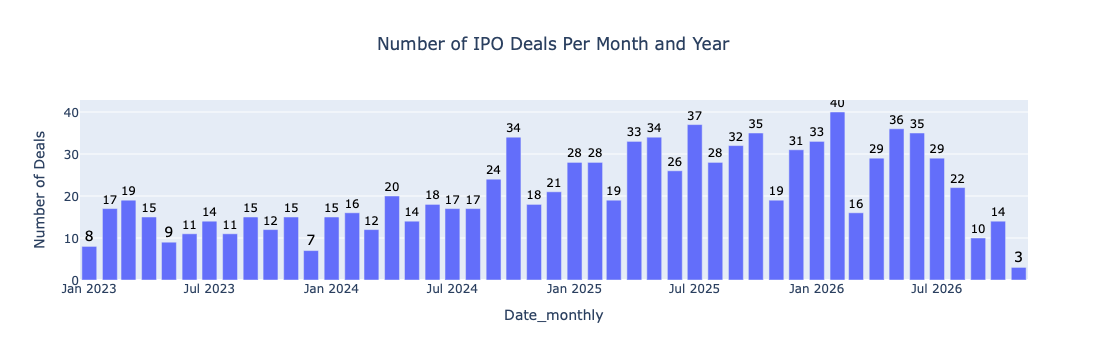

In [21]:
#some visualization: bar chart using plotly Express
import plotly.express as px
stacked_ipos_df['Date_monthly'] = stacked_ipos_df['IPO Date'].dt.to_period('M').dt.to_timestamp()

Monthly_Deals = stacked_ipos_df['Date_monthly'].value_counts().reset_index().sort_values(by = 'Date_monthly')
Monthly_Deals.columns = ['Date_monthly', 'Number of Deals']

fig = px.bar(Monthly_Deals,
            x = 'Date_monthly',
            y = 'Number of Deals',
            labels = {'Monthly_Year': 'Month and Year',
                     'Number of Deals' : 'Number of Deals'},
            title ='Number of IPO Deals Per Month and Year',
            text = 'Number of Deals'
            )
fig.update_traces(textposition ='outside',
                 textfont = dict(color='black',size = 14))
fig.update_layout(title_x = 0.5)
fig.show()

In [22]:
rddt_filter = stacked_ipos_df.Symbol == 'RDDT'
stacked_ipos_df[rddt_filter]

,IPO Date,Symbol,Company Name,IPO Price,Current,Return,Price Increase,Date_monthly
807,2024-03-21,RDDT,"Reddit, Inc.",34.0,98.45,1.8956,64.45,2024-03-01


In [23]:
#REDDIT - recent IPO
#https://finance.yahoo.com/quote/RDDT/
ticker_obj = yf.Ticker("RDDT")
reddit = ticker_obj.history(period = "max")
interval = "1d"
reddit.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-11-09 00:00:00-05:00,95.099998,101.404999,94.099998,100.790001,5879900,0.0,0.0
2026-11-10 00:00:00-05:00,98.910004,102.324997,95.080002,98.669998,5468200,0.0,0.0
2026-11-11 00:00:00-05:00,100.730003,106.379997,99.650002,105.660004,4959400,0.0,0.0
2026-11-12 00:00:00-05:00,101.269997,103.281998,98.510002,99.550003,5824400,0.0,0.0
2026-11-13 00:00:00-05:00,98.750000,100.589996,97.980003,98.449997,3254800,0.0,0.0


<Axes: title={'center': "Reddit's (RDDT) Price after the IPO"}, xlabel='Date'>

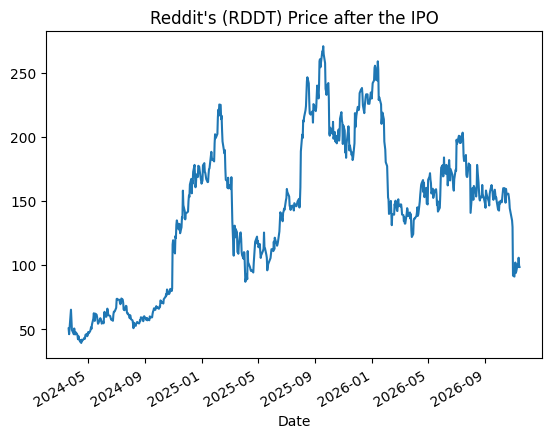

In [24]:
reddit['Close'].plot.line(title = 'Reddit\'s (RDDT) Price after the IPO')

In [25]:
ticker_obj = yf.Ticker("NVO")
nvo_df = ticker_obj.history(period = "max", interval = "1d")

In [26]:
nvo_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 11479 entries, 1981-04-30 00:00:00-04:00 to 2026-11-13 00:00:00-05:00
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          11479 non-null  float64
 1   High          11479 non-null  float64
 2   Low           11479 non-null  float64
 3   Close         11479 non-null  float64
 4   Volume        11479 non-null  int64  
 5   Dividends     11479 non-null  float64
 6   Stock Splits  11479 non-null  float64
dtypes: float64(6), int64(1)
memory usage: 717.4 KB


In [27]:
nvo_df.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-11-09 00:00:00-05:00,41.139999,41.630001,40.549999,41.380001,11761200,0.0,0.0
2026-11-10 00:00:00-05:00,40.709999,40.810001,40.380001,40.700001,6530900,0.0,0.0
2026-11-11 00:00:00-05:00,40.500000,41.200001,40.099998,41.090000,11707400,0.0,0.0
2026-11-12 00:00:00-05:00,40.930000,41.009998,40.080002,40.650002,15746600,0.0,0.0
2026-11-13 00:00:00-05:00,40.970001,41.799999,40.639999,41.630001,11698300,0.0,0.0


In [28]:
nvo_df_filtered_from_2020 = nvo_df[nvo_df.index >= '2020-01-01']
nvo_df_filtered_from_2024 = nvo_df[nvo_df.index >= '2024-01-01']

<Axes: title={'center': 'NOVO Nordisk A/S (NVO) Price daily'}, xlabel='Date'>

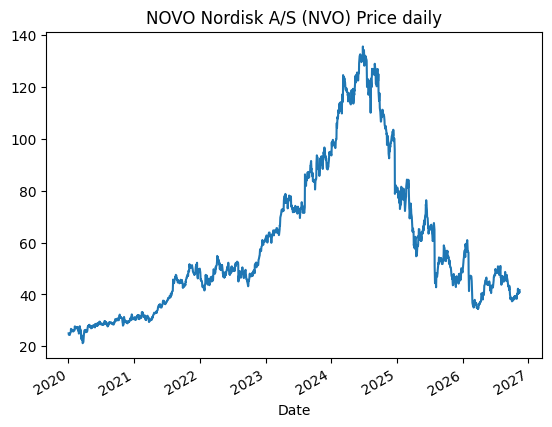

In [29]:
nvo_df_filtered_from_2020['Close'].plot.line(title = 'NOVO Nordisk A/S (NVO) Price daily')

In [30]:
nvo_df['Ticker'] = 'NVO'
nvo_df['Year'] = nvo_df.index.year
nvo_df['Month'] = nvo_df.index.month
nvo_df['Weekday'] = nvo_df.index.weekday
nvo_df['Date'] = nvo_df.index.date

In [31]:
nvo_df.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,Weekday,Date
Date,,,,,,,,,,,,
2026-11-09 00:00:00-05:00,41.139999,41.630001,40.549999,41.380001,11761200,0.0,0.0,NVO,2026,11,0,2026-11-09
2026-11-10 00:00:00-05:00,40.709999,40.810001,40.380001,40.700001,6530900,0.0,0.0,NVO,2026,11,1,2026-11-10
2026-11-11 00:00:00-05:00,40.500000,41.200001,40.099998,41.090000,11707400,0.0,0.0,NVO,2026,11,2,2026-11-11
2026-11-12 00:00:00-05:00,40.930000,41.009998,40.080002,40.650002,15746600,0.0,0.0,NVO,2026,11,3,2026-11-12
2026-11-13 00:00:00-05:00,40.970001,41.799999,40.639999,41.630001,11698300,0.0,0.0,NVO,2026,11,4,2026-11-13


In [32]:
nvo_df['Close_minus_1'] = nvo_df['Close'].shift(-1)
nvo_df['Close_plus_1'] = nvo_df['Close'].shift(+1)

nvo_df.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,Weekday,Date,Close_minus_1,Close_plus_1
Date,,,,,,,,,,,,,,
2026-11-09 00:00:00-05:00,41.139999,41.630001,40.549999,41.380001,11761200,0.0,0.0,NVO,2026,11,0,2026-11-09,40.700001,40.310001
2026-11-10 00:00:00-05:00,40.709999,40.810001,40.380001,40.700001,6530900,0.0,0.0,NVO,2026,11,1,2026-11-10,41.090000,41.380001
2026-11-11 00:00:00-05:00,40.500000,41.200001,40.099998,41.090000,11707400,0.0,0.0,NVO,2026,11,2,2026-11-11,40.650002,40.700001
2026-11-12 00:00:00-05:00,40.930000,41.009998,40.080002,40.650002,15746600,0.0,0.0,NVO,2026,11,3,2026-11-12,41.630001,41.090000
2026-11-13 00:00:00-05:00,40.970001,41.799999,40.639999,41.630001,11698300,0.0,0.0,NVO,2026,11,4,2026-11-13,NaN,40.650002


In [33]:
#historical growth
nvo_df['growth_1d'] = nvo_df['Close']/nvo_df['Close'].shift(1)
nvo_df['growth_30d'] = nvo_df['Close']/nvo_df['Close'].shift(30)

#Future growth for Regression models
nvo_df['growth_future_1d'] = nvo_df['Close'].shift(-1)/nvo_df['Close']
nvo_df['growth_future_30d'] = nvo_df['Close'].shift(-30)/nvo_df['Close']

#Future growth for binary models
nvo_df['is_positive_growth_1d_future'] = np.where(nvo_df['growth_future_1d'] > 1,1,0)
nvo_df['is_positive_growth_30d_future'] = np.where(nvo_df['growth_future_30d'] > 1,1,0)

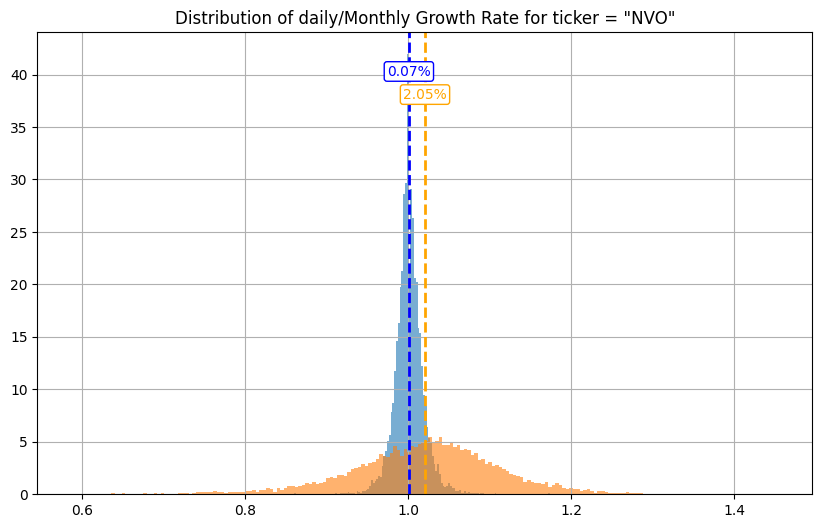

In [34]:
plt.figure(figsize = (10,6))
plt.title('Distribution of daily/Monthly Growth Rate for ticker = "NVO"')

nvo_df.growth_1d.hist(bins = 200, alpha = 0.6, density = True)
nvo_df.growth_30d.hist(bins = 200, alpha = 0.6, density = True)

#Adding vertical line for averages
mean_1d = nvo_df.growth_1d.mean()
mean_30d = nvo_df.growth_30d.mean()

plt.axvline(mean_1d,color = 'blue', linestyle = '--', linewidth = 2, label = f'1d avg = {mean_1d:.3f}')
plt.axvline(mean_30d,color = 'orange', linestyle = '--',linewidth = 2,label = f'30d avg = {mean_30d:.3f}')

#Adding mean text labels (as percentage change) 
ymax = plt.ylim()[1]
plt.text(mean_1d,ymax * 0.90,
        f'{(mean_1d-1)*100:.2f}%',
        color = 'blue', ha ='center', va = 'bottom',bbox = dict(facecolor ='white', edgecolor = 'blue',boxstyle = 'round, pad = 0.2'
                                                               )
         )
plt.text(mean_30d,ymax * 0.85,
        f'{(mean_30d-1)*100:.2f}%',
        color = 'orange', ha ='center', va = 'bottom',bbox = dict(facecolor ='white', edgecolor = 'orange',boxstyle = 'round, pad = 0.2'
                                                               )
         )
plt.show()


<Axes: title={'center': 'Distribution of 2 Days Growth Rates for ticker = "NVO"'}>

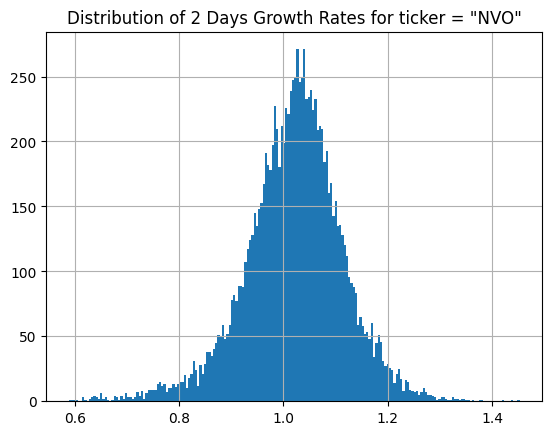

In [35]:
# we can see that the growth can be much wider in 30d
plt.title('Distribution of 2 Days Growth Rates for ticker = "NVO"')
nvo_df.growth_30d.hist(bins = 200)

In [36]:
# for modelling we use growth-1d,growth-2d as a feeature
COLUMNS = [k for k in nvo_df.keys() 
           if k.find('growth') >= 0 or k == 'Close']
nvo_df[COLUMNS].tail()

,Close,growth_1d,growth_30d,growth_future_1d,growth_future_30d,is_positive_growth_1d_future,is_positive_growth_30d_future
Date,,,,,,,
2026-11-09 00:00:00-05:00,41.380001,1.026544,1.068974,0.983567,NaN,0,0
2026-11-10 00:00:00-05:00,40.700001,0.983567,1.062386,1.009582,NaN,1,0
2026-11-11 00:00:00-05:00,41.090000,1.009582,1.083883,0.989292,NaN,0,0
2026-11-12 00:00:00-05:00,40.650002,0.989292,1.086898,1.024108,NaN,1,0
2026-11-13 00:00:00-05:00,41.630001,1.024108,1.115488,NaN,NaN,0,0


In [37]:
#calculate the distribution of future growth 
nvo_df.is_positive_growth_1d_future.value_counts() / len(nvo_df)

is_positive_growth_1d_future
0    0.513198
1    0.486802
Name: count, dtype: float64

In [38]:
nvo_df.is_positive_growth_30d_future.value_counts() / len(nvo_df)

is_positive_growth_30d_future
1    0.615036
0    0.384964
Name: count, dtype: float64

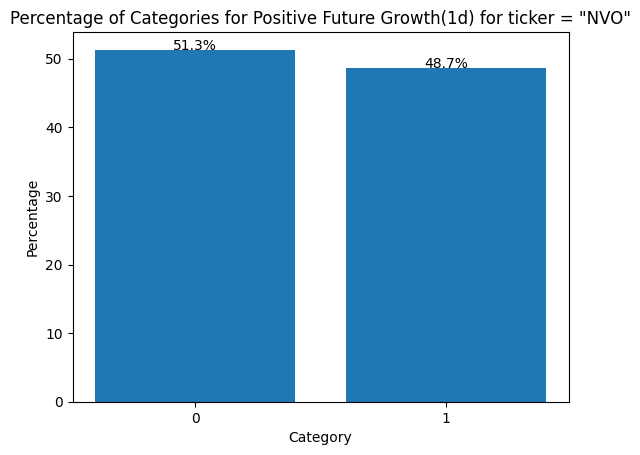

In [39]:
#calculate the value count
value_counts = nvo_df['is_positive_growth_1d_future'].value_counts()
#calculate the percentage of each category
percentage  = (value_counts/ len(nvo_df) * 100)

#plotting a  bar chart
plt.bar(percentage.index.astype(str), percentage)
plt.xlabel('Category')
plt.ylabel('Percentage')
plt.title('Percentage of Categories for Positive Future Growth(1d) for ticker = "NVO"')

#Add percentage value on top of each bar
for i, value in enumerate(percentage):
    plt.text(i,value + 0,f'{value:.1f}%', ha = 'center')
    
plt.show()

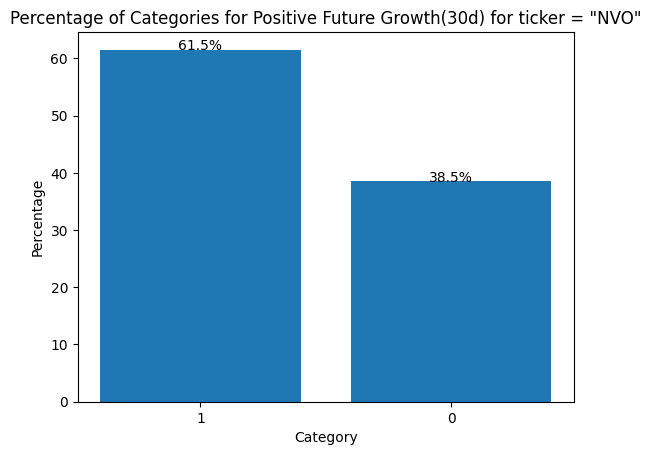

In [40]:
#calculate the value count
value_counts = nvo_df['is_positive_growth_30d_future'].value_counts()
#calculate the percentage of each category
percentage  = (value_counts/ len(nvo_df) * 100)

#plotting a  bar chart
plt.bar(percentage.index.astype(str), percentage)
plt.xlabel('Category')
plt.ylabel('Percentage')
plt.title('Percentage of Categories for Positive Future Growth(30d) for ticker = "NVO"')

#Add percentage value on top of each bar
for i, value in enumerate(percentage):
    plt.text(i,value + 0,f'{value:.1f}%', ha = 'center')
    
plt.show()

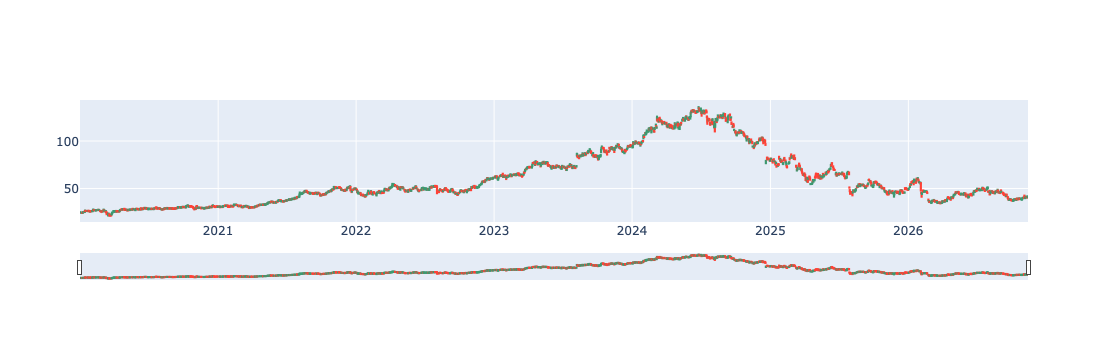

In [41]:
#candlestick charts: https://plotly.com/python/candlestick.charts
import plotly.graph_objects as go

fig = go.Figure(data=[go.Candlestick(
    x = nvo_df_filtered_from_2020.index,
    open = nvo_df_filtered_from_2020.Open,
    high = nvo_df_filtered_from_2020.High,
    low = nvo_df_filtered_from_2020.Low,
    close = nvo_df_filtered_from_2020.Close
)])

fig.show()

In [42]:
#Macro Indicators
end = date.today()
print(f'year = {end.year}; month = {end.month}; day = {end.day}')

start = date(year = end.year - 70,month = end.month, day = end.day)
print(f'Period for indexes:{start} to {end}')

year = 2026; month = 11; day = 16
Period for indexes:1956-11-16 to 2026-11-16


In [43]:
ticker_obj = yf.Ticker("^GDAXI")
dax_daily = ticker_obj.history(period = "max", interval = "1d")

In [44]:
for i in [1,3,7,30,90,365]:
    dax_daily['growth_dax_'+str(i)+'d'] = dax_daily['Close']/dax_daily['Close'].shift(i)

In [45]:
dax_daily.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,,,,,,,,
1987-12-30 00:00:00+01:00,1005.190002,1005.190002,1005.190002,1005.190002,0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1988-01-04 00:00:00+01:00,956.489990,956.489990,956.489990,956.489990,0,0.0,0.0,0.951551,NaN,NaN,NaN,NaN,NaN
1988-01-05 00:00:00+01:00,996.099976,996.099976,996.099976,996.099976,0,0.0,0.0,1.041412,NaN,NaN,NaN,NaN,NaN
1988-01-06 00:00:00+01:00,1006.010010,1006.010010,1006.010010,1006.010010,0,0.0,0.0,1.009949,1.000816,NaN,NaN,NaN,NaN
1988-01-07 00:00:00+01:00,1014.469971,1014.469971,1014.469971,1014.469971,0,0.0,0.0,1.008409,1.060617,NaN,NaN,NaN,NaN


In [46]:
dax_daily.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,,,,,,,,
2026-11-09 00:00:00+01:00,25815.300781,26276.089844,25793.060547,26267.189453,57229100,0.0,0.0,1.017305,0.993552,1.008737,1.035184,1.017403,1.082002
2026-11-10 00:00:00+01:00,26548.589844,26633.779297,26347.449219,26347.449219,64007300,0.0,0.0,1.003056,1.000852,1.020499,1.037333,1.034643,1.083206
2026-11-11 00:00:00+01:00,26623.339844,26662.769531,26491.769531,26662.769531,54422100,0.0,0.0,1.011968,1.032626,1.026238,1.058080,1.070904,1.097032
2026-11-12 00:00:00+01:00,26910.570312,27001.669922,26671.449219,26771.880859,58399000,0.0,0.0,1.004092,1.019214,1.035077,1.073480,1.065833,1.107451
2026-11-13 00:00:00+01:00,26697.029297,26832.820312,26678.349609,26749.949219,50657800,0.0,0.0,0.999181,1.015277,1.011812,1.060193,1.067134,1.115159


In [47]:
GROWTH_KEYS = [k for k in dax_daily.keys() if k.startswith ('growth')]
dax_daily_to_merge = dax_daily[GROWTH_KEYS]
dax_daily_to_merge.tail(1)

,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,
2026-11-13 00:00:00+01:00,0.999181,1.015277,1.011812,1.060193,1.067134,1.115159


In [48]:
def get_growth_df(df:pd.DataFrame, prefix:str)->pd.DataFrame:
  for i in [1,3,7,30,90,365]:
    df['growth_'+prefix+'_'+str(i)+'d'] = df['Close'] / df['Close'].shift(i)
    GROWTH_KEYS = [k for k in df.keys() if k.startswith('growth')]
  return df[GROWTH_KEYS]

In [49]:
ticker_obj = yf.Ticker("^GSPC")
snp500_daily = ticker_obj.history(
    period ="max",
    interval = "1d"
)

In [50]:
snp500_to_merge = get_growth_df(snp500_daily,'snp500')
snp500_to_merge.tail(2)

,growth_snp500_1d,growth_snp500_3d,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d
Date,,,,,,
2026-11-12 00:00:00-05:00,0.996459,1.005624,1.003102,0.990341,1.014659,1.279056
2026-11-13 00:00:00-05:00,0.995953,1.005417,0.983489,0.979146,1.002390,1.266533


In [51]:
ticker_obj = yf.Ticker("^DJI")
dji_daily = ticker_obj.history(
    period = "max",
    interval = "1d"
)

In [52]:
dji_daily_to_merge = get_growth_df(dji_daily,'dji')
dji_daily_to_merge.tail(2)

,growth_dji_1d,growth_dji_3d,growth_dji_7d,growth_dji_30d,growth_dji_90d,growth_dji_365d
Date,,,,,,
2026-11-12 00:00:00-05:00,0.996391,0.998231,1.009855,1.026912,0.999020,1.236178
2026-11-13 00:00:00-05:00,1.000965,1.002214,0.981097,1.022873,0.997335,1.231138


In [53]:
ticker_obj = yf.Ticker("EPI")
epi_etf_daily = ticker_obj.history(
                     period = "max",
                     interval = "1d")

epi_etf_daily.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Capital Gains
Date,,,,,,,,
2026-11-12 00:00:00-05:00,44.200001,44.290001,44.110001,44.180000,388600,0.0,0.0,0.0
2026-11-13 00:00:00-05:00,43.930000,44.130001,43.849998,44.130001,264400,0.0,0.0,0.0


In [54]:
epi_etf_daily_to_merge = get_growth_df(epi_etf_daily,'epi')
epi_etf_daily_to_merge.tail(2)

,growth_epi_1d,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d
Date,,,,,,
2026-11-12 00:00:00-05:00,0.997291,1.004319,1.060490,1.092483,1.048908,0.949291
2026-11-13 00:00:00-05:00,0.998868,0.997514,1.028192,1.088823,1.042523,0.958306


In [55]:
gdppot = pdr.DataReader("GDPPOT","fred",start = start)
gdppot['gdppot_us_yoy'] = gdppot.GDPPOT/gdppot.GDPPOT.shift(4)-1
gdppot['gdppot_us_qoq'] = gdppot.GDPPOT/gdppot.GDPPOT.shift(1)-1
gdppot.tail(2)

,GDPPOT,gdppot_us_yoy,gdppot_us_qoq
DATE,,,
2026-07-01,24200.444694,0.021972,0.005380
2026-10-01,24330.374529,0.021803,0.005369


In [56]:
gdppot_to_merge = gdppot[['gdppot_us_yoy','gdppot_us_qoq']]
gdppot_to_merge.tail(1)

,gdppot_us_yoy,gdppot_us_qoq
DATE,,
2026-10-01,0.021803,0.005369


In [57]:
cpilfesl = pdr.DataReader("CPILFESL","fred",start = start)
cpilfesl['cpi_core_yoy'] = cpilfesl.CPILFESL/cpilfesl.CPILFESL.shift(12)-1
cpilfesl['cpi_core_mom'] = cpilfesl.CPILFESL/cpilfesl.CPILFESL.shift(1)-1
cpilfesl.tail(2)

,CPILFESL,cpi_core_yoy,cpi_core_mom
DATE,,,
2026-09-01,338.896,0.025658,0.003348
2026-10-01,339.900,NaN,0.002963


In [58]:
cpilfesl_to_merge = cpilfesl[['cpi_core_yoy','cpi_core_mom']]
cpilfesl_to_merge.tail(2)

,cpi_core_yoy,cpi_core_mom
DATE,,
2026-09-01,0.025658,0.003348
2026-10-01,NaN,0.002963


In [59]:
fedfunds = pdr.DataReader("FEDFUNDS","fred",start = start)
fedfunds.tail(2)

,FEDFUNDS
DATE,
2026-09-01,3.75
2026-10-01,3.88


In [60]:
dgs1 = pdr.DataReader("DGS1","fred",start = start)
dgs1.tail(2)

,DGS1
DATE,
2026-11-11,NaN
2026-11-12,4.65


In [61]:
dgs5 = pdr.DataReader("DGS5","fred",start = start)
dgs5.tail(2)

,DGS5
DATE,
2026-11-11,NaN
2026-11-12,4.95


In [62]:
dgs10 = pdr.DataReader("DGS10","fred",start = start)
dgs10.tail(2)

,DGS10
DATE,
2026-11-11,NaN
2026-11-12,5.1


In [63]:
ticker_obj = yf.Ticker("^VIX")
vix = ticker_obj.history(
    period = "max",
    interval = "1d"
)
vix.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-11-12 00:00:00-06:00,18.360001,19.34,17.379999,18.700001,0,0.0,0.0
2026-11-13 00:00:00-06:00,18.780001,20.92,17.639999,19.299999,0,0.0,0.0


In [64]:
vix_to_merge = vix['Close']
vix_to_merge.tail()

Date
2026-11-09 00:00:00-06:00    19.920000
2026-11-10 00:00:00-06:00    19.459999
2026-11-11 00:00:00-06:00    17.490000
2026-11-12 00:00:00-06:00    18.700001
2026-11-13 00:00:00-06:00    19.299999
Name: Close, dtype: float64

<Axes: title={'center': 'VIX value over time'}, xlabel='Date'>

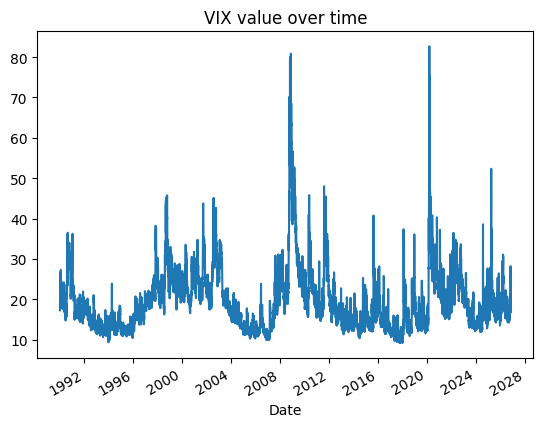

In [65]:
# we want to plot a static graph that is hard to zoom in to give us the exact dates of the spikes
vix['Close'].plot.line(title = "VIX value over time")

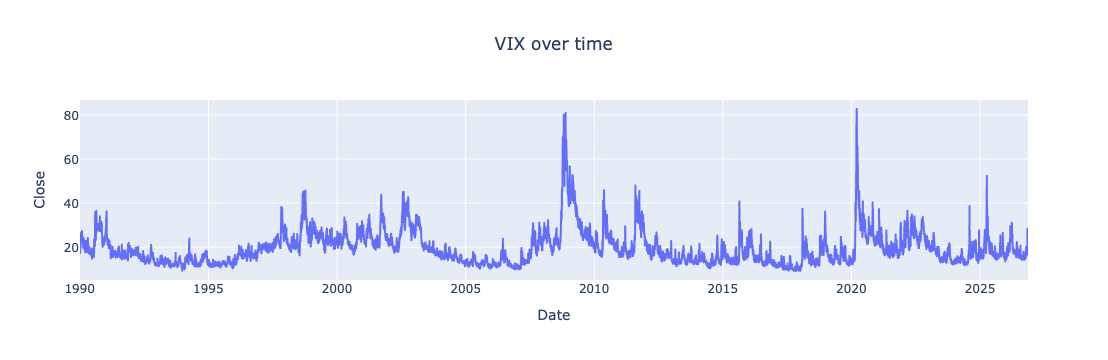

In [66]:
#now we want to do a dynamic visualization of the plot
fig = px.line(
    vix,
    x =vix.index,
    y = "Close",
    title = 'VIX over time'
)
fig.update_layout(title_x = 0.5)
fig.show()

In [67]:
ticker_obj = yf.Ticker("GC=F")
gold = ticker_obj.history(
    period = "max",
    interval = "1d"
)
gold.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-11-16 00:00:00-05:00,3869.699951,3904.300049,3835.199951,3858.199951,60320,0.0,0.0


In [68]:
gold_to_merge = get_growth_df(gold,'gold')
gold_to_merge.tail(2)

,growth_gold_1d,growth_gold_3d,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d
Date,,,,,,
2026-11-13 00:00:00-05:00,1.000257,0.964295,0.954162,0.933691,0.938539,1.143298
2026-11-16 00:00:00-05:00,0.992769,0.964429,0.937936,0.928166,0.937890,1.143136


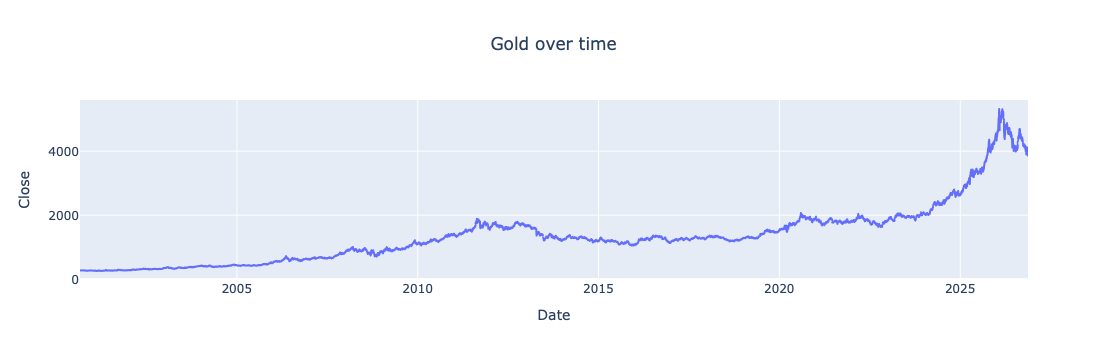

In [69]:
#Dynamic visualization of the gold plot
fig = px.line(gold,
             x=gold.index,
             y= "Close",
             title = 'Gold over time')
fig.update_layout(title_x = 0.5)
fig.show()

In [70]:
ticker_obj = yf.Tickers("CL=F")
crude_oil = ticker_obj.history(
    period = "max",
    interval = "1d"
)
crude_oil.tail(2)

[*********************100%***********************]  1 of 1 completed


Price,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,CL=F,CL=F,CL=F,CL=F,CL=F,CL=F,CL=F
Date,,,,,,,
2026-11-13,88.559998,0.0,89.639999,87.800003,88.790001,0.0,270072
2026-11-16,88.690002,0.0,89.470001,87.589996,88.650002,0.0,20794


In [71]:
crude_oil.columns = crude_oil.columns.get_level_values(0)

crude_oil_to_merge = get_growth_df(crude_oil,'wti_oil')
crude_oil_to_merge.tail(2)
     

Price,growth_wti_oil_1d,growth_wti_oil_3d,growth_wti_oil_7d,growth_wti_oil_30d,growth_wti_oil_90d,growth_wti_oil_365d
Date,,,,,,
2026-11-13,0.997972,1.029289,1.004993,0.972012,1.228635,1.409069
2026-11-16,1.001468,1.024962,0.979784,0.991725,1.241983,1.399558


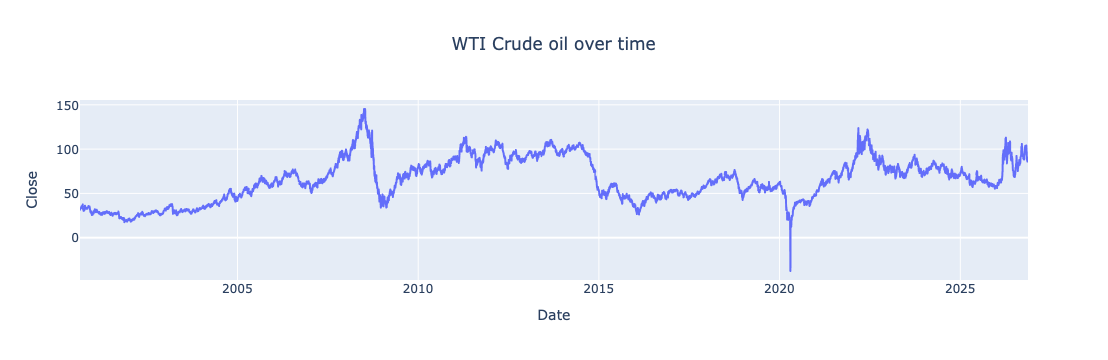

In [72]:
#dynamic visualization of the plot
fig = px.line(crude_oil,
             x = crude_oil.index,
             y ="Close",
             title = 'WTI Crude oil over time')
fig.update_layout(title_x = 0.5)
fig.show()

In [73]:
ticker_obj = yf.Tickers("BZ=F")
brent_oil = ticker_obj.history(
    period = "max",
    interval = "1d"
)
brent_oil.tail(2)

[*********************100%***********************]  1 of 1 completed


Price,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,BZ=F,BZ=F,BZ=F,BZ=F,BZ=F,BZ=F,BZ=F
Date,,,,,,,
2026-11-13,95.839996,0.0,97.120003,95.070000,95.889999,0.0,35151
2026-11-16,95.820000,0.0,96.760002,94.459999,95.839996,0.0,2383


In [74]:
brent_oil.columns = brent_oil.columns.get_level_values(0)

brent_oil_to_merge = get_growth_df(brent_oil,'brent_oil')
brent_oil_to_merge.tail(2)

Price,growth_brent_oil_1d,growth_brent_oil_3d,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d
Date,,,,,,
2026-11-13,1.000209,1.047546,1.012894,0.937310,1.256094,1.477644
2026-11-16,0.999791,1.032988,0.974870,0.955144,1.260624,1.466483


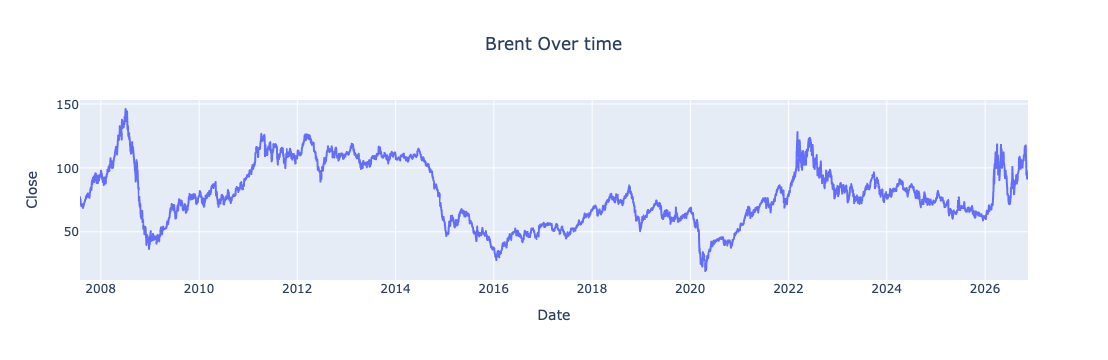

In [75]:
fig = px.line(brent_oil,
             x = brent_oil.index,
             y ="Close",
             title ='Brent Over time')
fig.update_layout(title_x =0.5)
fig.show()

In [76]:
ticker_obj = yf.Tickers("BTC-USD")
btc_usd = ticker_obj.history(
    period = "max",
    interval = "1d"
)
btc_usd.tail(2)

[*********************100%***********************]  1 of 1 completed


Price,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,,,
2026-11-15,65305.062500,0.0,66055.101562,62017.882812,64128.050781,0.0,39757267458
2026-11-16,64935.511719,0.0,65363.437500,64254.113281,65314.550781,0.0,29774530560


In [77]:
btc_usd.columns = btc_usd.columns.get_level_values(0)

btc_usd_to_merge = get_growth_df(btc_usd,'btc_usd')
btc_usd_to_merge.tail(2)

Price,growth_btc_usd_1d,growth_btc_usd_3d,growth_btc_usd_7d,growth_btc_usd_30d,growth_btc_usd_90d,growth_btc_usd_365d
Date,,,,,,
2026-11-15,1.018354,0.915368,0.875583,0.801281,1.012383,0.683471
2026-11-16,0.994341,0.951446,0.863238,0.797909,1.003939,0.689504


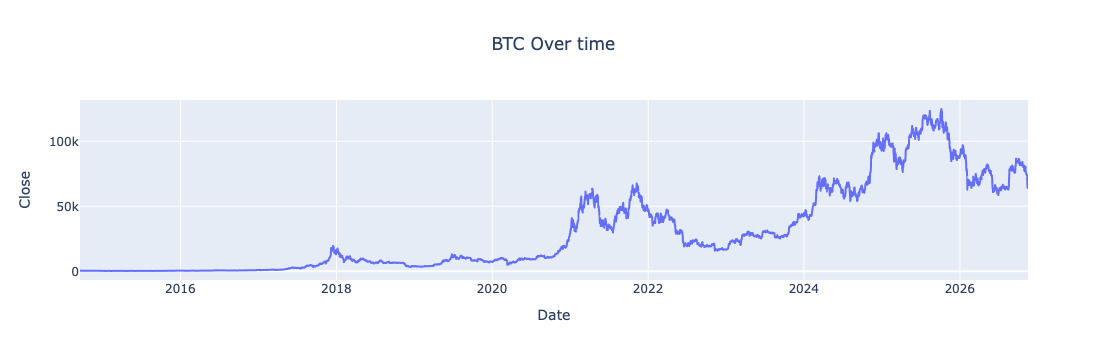

In [78]:
fig = px.line(btc_usd,
            x = btc_usd.index,
            y = "Close",
            title = "BTC Over time" 
            )
fig.update_layout(title_x = 0.5)
fig.show()

In [79]:
#EUROSTAT THE HOME OF HIGH QUALITY DATA AND STATISTICS ON EUROPE
import eurostat

In [80]:
filter_pars = {'startPeriod':'2026-08-31', 'endPeriod':'2026-11-12'}

code = 'irt_euryld_d'
eurostat_euro_yield_df = eurostat.get_data_df(code, flags=True, filter_pars=filter_pars,  verbose=True)

Download progress: 100.0%



In [81]:
eurostat_euro_yield_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2148 entries, 0 to 2147
Columns: 113 entries, freq to 2026-11-12_flag
dtypes: float64(54), object(59)
memory usage: 1.9+ MB


In [82]:
eurostat_euro_yield_df.head()

,freq,yld_curv,maturity,bonds,geo\TIME_PERIOD,2026-08-31_value,2026-08-31_flag,2026-09-01_value,2026-09-01_flag,2026-09-02_value,...,2026-11-06_value,2026-11-06_flag,2026-11-09_value,2026-11-09_flag,2026-11-10_value,2026-11-10_flag,2026-11-11_value,2026-11-11_flag,2026-11-12_value,2026-11-12_flag
0,D,INS_FWD,M10,CGB_EA,EA,2.99586,,3.01466,,3.06000,...,3.11283,,3.10648,,3.20320,,3.24345,,3.29402,
1,D,INS_FWD,M10,CGB_EA_AAA,EA,2.91537,,2.93919,,2.98761,...,2.99979,,3.00841,,3.10262,,3.14058,,3.16754,
2,D,INS_FWD,M11,CGB_EA,EA,3.01626,,3.03579,,3.08304,...,3.13243,,3.12691,,3.22408,,3.26504,,3.31643,
3,D,INS_FWD,M11,CGB_EA_AAA,EA,2.93753,,2.96217,,3.01071,...,3.01194,,3.02014,,3.11733,,3.15538,,3.18435,
4,D,INS_FWD,M3,CGB_EA,EA,2.65833,,2.66916,,2.69979,...,2.86594,,2.87123,,2.91601,,2.93150,,2.93890,


In [83]:
eurostat_euro_yield_df['maturity'].value_counts()

maturity
Y9_M9      6
M10        6
M11        6
M3         6
M4         6
          ..
Y1         6
Y10        6
Y10_M1     6
Y10_M10    6
Y10_M11    6
Name: count, Length: 358, dtype: int64

In [84]:
eurostat_euro_yield_df['yld_curv'].value_counts()

yld_curv
INS_FWD    716
PAR        716
SPOT_RT    716
Name: count, dtype: int64

In [85]:
eurostat_euro_yield_df

,freq,yld_curv,maturity,bonds,geo\TIME_PERIOD,2026-08-31_value,2026-08-31_flag,2026-09-01_value,2026-09-01_flag,2026-09-02_value,...,2026-11-06_value,2026-11-06_flag,2026-11-09_value,2026-11-09_flag,2026-11-10_value,2026-11-10_flag,2026-11-11_value,2026-11-11_flag,2026-11-12_value,2026-11-12_flag
0,D,INS_FWD,M10,CGB_EA,EA,2.99586,,3.01466,,3.06000,...,3.11283,,3.10648,,3.20320,,3.24345,,3.29402,
1,D,INS_FWD,M10,CGB_EA_AAA,EA,2.91537,,2.93919,,2.98761,...,2.99979,,3.00841,,3.10262,,3.14058,,3.16754,
2,D,INS_FWD,M11,CGB_EA,EA,3.01626,,3.03579,,3.08304,...,3.13243,,3.12691,,3.22408,,3.26504,,3.31643,
3,D,INS_FWD,M11,CGB_EA_AAA,EA,2.93753,,2.96217,,3.01071,...,3.01194,,3.02014,,3.11733,,3.15538,,3.18435,
4,D,INS_FWD,M3,CGB_EA,EA,2.65833,,2.66916,,2.69979,...,2.86594,,2.87123,,2.91601,,2.93150,,2.93890,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2143,D,SPOT_RT,Y9_M7,CGB_EA_AAA,EA,3.31259,,3.32831,,3.36502,...,3.26405,,3.25059,,3.31050,,3.31940,,3.34699,
2144,D,SPOT_RT,Y9_M8,CGB_EA,EA,3.74107,,3.75831,,3.79659,...,3.86979,,3.83823,,3.88903,,3.90213,,3.92726,
2145,D,SPOT_RT,Y9_M8,CGB_EA_AAA,EA,3.31804,,3.33373,,3.37044,...,3.26841,,3.25491,,3.31462,,3.32358,,3.35108,
2146,D,SPOT_RT,Y9_M9,CGB_EA,EA,3.74834,,3.76556,,3.80375,...,3.87635,,3.84455,,3.89519,,3.90829,,3.93342,


In [86]:
# Visual graph: https://www.ecb.europa.eu/stats/financial_markets_and_interest_rates/euro_area_yield_curves/html/index.en.html
FILTER = (eurostat_euro_yield_df.yld_curv == 'SPOT_RT') & (eurostat_euro_yield_df.bonds == 'CGB_EA_AAA')
filtered_eurostat_euro_yield_df = eurostat_euro_yield_df[FILTER]

In [87]:
filtered_eurostat_euro_yield_df.sort_values(by= 'maturity')[['maturity','2026-09-01_value']].head(20)

,maturity,2026-09-01_value
1433,M10,2.68217
1435,M11,2.70662
1437,M3,2.42149
1439,M4,2.47067
1441,M5,2.51524
1443,M6,2.55561
1445,M7,2.59215
1447,M8,2.62522
1449,M9,2.65513
1451,Y1,2.72871


In [88]:
import re
def extract_numbers(input_string):
    y_match = re.search(r'Y(\d+)',input_string)
    m_match = re.search(r'M(\d+)',input_string)

    y_number = int(y_match.group(1)) if y_match else 0
    m_number = int(m_match.group(1)) if m_match else 0

    return y_number*12 + m_number
# A good example
examples =  ["Y10_M2","M3","Y1"]
for example in examples:
    res = extract_numbers(example)
    print(f"{example} ==>{res}")

Y10_M2 ==>122
M3 ==>3
Y1 ==>12


In [89]:
#define new field:"maturity in months"
filtered_eurostat_euro_yield_df.loc[:,'maturity_in_months'] = filtered_eurostat_euro_yield_df.maturity.apply(lambda x:extract_numbers(x))

/var/folders/2d/1c91gggs08n6vxd8g4bhwqmc0001yj/T/ipykernel_45064/1827550511.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_eurostat_euro_yield_df.loc[:,'maturity_in_months'] = filtered_eurostat_euro_yield_df.maturity.apply(lambda x:extract_numbers(x))


In [90]:
filtered_eurostat_euro_yield_df.sort_values(by='maturity_in_months')[['maturity','maturity_in_months','2026-09-01_value']].head(20)

,maturity,maturity_in_months,2026-09-01_value
1437,M3,3,2.42149
1439,M4,4,2.47067
1441,M5,5,2.51524
1443,M6,6,2.55561
1445,M7,7,2.59215
1447,M8,8,2.62522
1449,M9,9,2.65513
1433,M10,10,2.68217
1435,M11,11,2.70662
1451,Y1,12,2.72871


In [91]:
filtered_eurostat_euro_yield_df.loc [ :,'maturity_in_years'] = filtered_eurostat_euro_yield_df.maturity_in_months/12.0

/var/folders/2d/1c91gggs08n6vxd8g4bhwqmc0001yj/T/ipykernel_45064/3183468280.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_eurostat_euro_yield_df.loc [ :,'maturity_in_years'] = filtered_eurostat_euro_yield_df.maturity_in_months/12.0


<Axes: title={'center': 'AAA rated bonds spot yield curve'}, xlabel='maturity_in_years'>

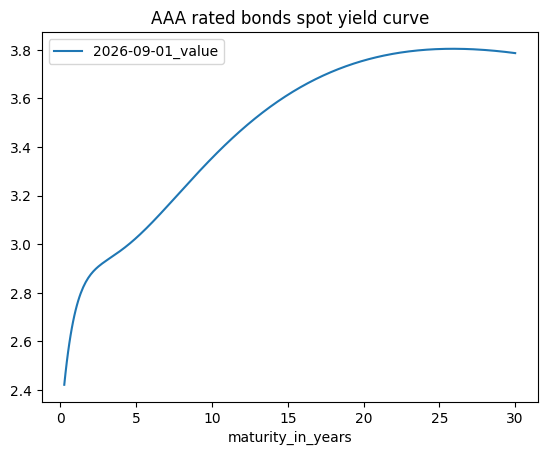

In [92]:
filtered_eurostat_euro_yield_df \
  .sort_values(by='maturity_in_months')[['maturity_in_years','2026-09-01_value']] \
  .plot.line(x='maturity_in_years',
            y='2026-09-01_value',
            title='AAA rated bonds spot yield curve')
     

     

     



In [93]:
#fundamental analysis

In [94]:
#let us select some of the stocks:top us companies on 'Employees'
US_TOP_EMPLOYEES_STOCKS = ['WMT','AMZN','UPS','HD','CNXC','TGT','KR','UNH','BRK-B','SBUX']

ticker = US_TOP_EMPLOYEES_STOCKS[0]
one_company = yf.Ticker(ticker)

In [95]:
eps_earnings = one_company.earnings_dates
eps_earnings['Ticker'] = ticker
eps_earnings

,EPS Estimate,Reported EPS,Surprise(%),Ticker
Earnings Date,,,,
2026-11-19 08:00:00-05:00,0.64,NaN,NaN,WMT
2026-08-20 08:00:00-04:00,0.74,NaN,NaN,WMT
2026-05-21 06:00:00-04:00,0.66,0.66,0.19,WMT
2026-02-19 06:00:00-05:00,0.73,0.74,1.79,WMT
2025-11-20 06:00:00-05:00,0.60,0.62,3.11,WMT
2025-08-21 06:00:00-04:00,0.74,0.68,-7.97,WMT
2025-05-15 06:00:00-04:00,0.58,0.61,5.64,WMT
2025-02-20 06:00:00-05:00,0.65,0.66,2.04,WMT
2024-11-19 06:00:00-05:00,0.53,0.58,8.84,WMT


In [96]:
one_company.calendar

{'Dividend Date': datetime.date(2027, 1, 4),
 'Ex-Dividend Date': datetime.date(2026, 12, 11),
 'Earnings Date': [datetime.date(2026, 11, 19)],
 'Earnings High': 0.66,
 'Earnings Low': 0.61,
 'Earnings Average': 0.6356,
 'Revenue High': 189775000000,
 'Revenue Low': 185607000000,
 'Revenue Average': 187256605980}

In [97]:
one_company.financials

,2026-01-31,2025-01-31,2024-01-31,2023-01-31,2022-01-31
Tax Effect Of Unusual Items,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN
Tax Rate For Calcs,2.442910e-01,2.338360e-01,2.550000e-01,3.360000e-01,NaN
Normalized EBITDA,4.647100e+10,4.201000e+10,3.638400e+10,3.008900e+10,NaN
Total Unusual Items,NaN,NaN,0.000000e+00,0.000000e+00,-2.410000e+09
Total Unusual Items Excluding Goodwill,NaN,NaN,0.000000e+00,0.000000e+00,-2.410000e+09
Net Income From Continuing Operation Net Minority Interest,2.189300e+10,1.943600e+10,1.551100e+10,1.168000e+10,NaN
Reconciled Depreciation,1.420300e+10,1.297300e+10,1.185300e+10,1.094500e+10,NaN
Reconciled Cost Of Revenue,5.353950e+11,5.117530e+11,4.901420e+11,4.637210e+11,NaN
EBITDA,4.647100e+10,4.201000e+10,3.638400e+10,3.008900e+10,NaN
EBIT,3.226800e+10,2.903700e+10,2.453100e+10,1.914400e+10,NaN


In [98]:
EPS = one_company.financials.loc['Basic EPS']
EPS

2026-01-31    2.74
2025-01-31    2.42
2024-01-31    1.92
2023-01-31    1.43
2022-01-31     NaN
Name: Basic EPS, dtype: float64

In [99]:
#using the Normalized_EBITDA
EBITDA = one_company.financials.loc['EBITDA']
EBITDA_margin = one_company.financials.loc['EBITDA']/one_company.financials.loc['Total Revenue']

In [100]:
EBITDA_margin

2026-01-31    0.065162
2025-01-31    0.061690
2024-01-31    0.056137
2023-01-31    0.049222
2022-01-31         NaN
dtype: float64

In [101]:
NET_INCOME = one_company.financials.loc['Net Income']
NET_INCOME_margin = one_company.financials.loc['Net Income']/one_company.financials.loc['Total Revenue']
NET_INCOME_margin

2026-01-31    0.030698
2025-01-31    0.028541
2024-01-31    0.023932
2023-01-31    0.019107
2022-01-31         NaN
dtype: float64

In [102]:
NET_INCOME

2026-01-31    2.189300e+10
2025-01-31    1.943600e+10
2024-01-31    1.551100e+10
2023-01-31    1.168000e+10
2022-01-31             NaN
Name: Net Income, dtype: float64

In [103]:
#Combining the series into a dataframe

df_fin_ratios = pd.DataFrame({
    'NET_INCOME_margin': 100 * NET_INCOME_margin,
    'EBITDA_margin' : 100 * EBITDA_margin,
    'EPS' : EPS
})

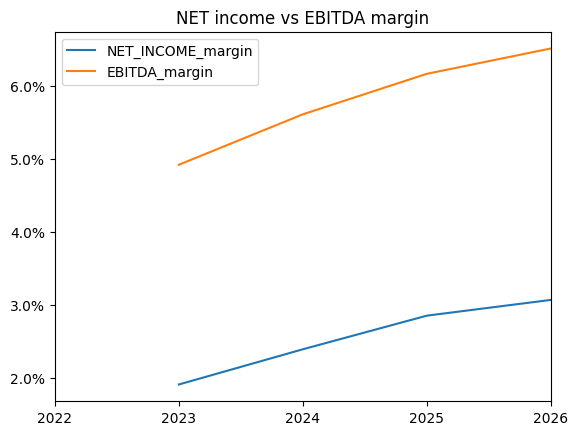

In [104]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ax = df_fin_ratios[['NET_INCOME_margin','EBITDA_margin']].plot.line()

ax.yaxis.set_major_formatter(mtick.PercentFormatter())


plt.title('NET income vs EBITDA margin')
plt.show()

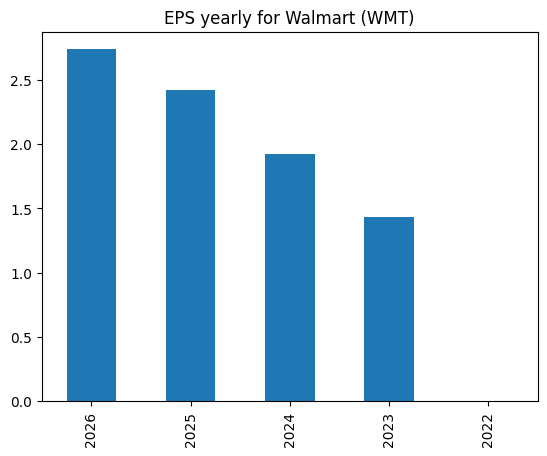

In [105]:
EPS_year = df_fin_ratios['EPS'].index.year

df_fin_ratios['EPS'].plot.bar(title = 'EPS yearly for Walmart (WMT)')

plt.xticks(range(len(EPS_year)), EPS_year)

plt.show()

In [106]:
# https://companiesmarketcap.com/usa/largest-companies-in-the-usa-by-market-cap/
US_STOCKS = ['MSFT', 'AAPL', 'GOOG', 'NVDA', 'AMZN', 'META', 'BRK-B', 'LLY', 'AVGO','V', 'JPM']
# https://companiesmarketcap.com/european-union/largest-companies-in-the-eu-by-market-cap/
EU_STOCKS = ['NVO','MC.PA', 'ASML', 'RMS.PA', 'OR.PA', 'SAP', 'ACN', 'TTE', 'SIE.DE','IDEXY','CDI.PA']
# https://companiesmarketcap.com/india/largest-companies-in-india-by-market-cap/
INDIA_STOCKS = ['RELIANCE.NS','TCS.NS','HDB','BHARTIARTL.NS','IBN','SBIN.NS','LICI.NS','INFY','ITC.NS','HINDUNILVR.NS','LT.NS']
     

In [107]:
ALL_TICKERS = US_STOCKS + EU_STOCKS + INDIA_STOCKS
ALL_TICKERS

['MSFT',
 'AAPL',
 'GOOG',
 'NVDA',
 'AMZN',
 'META',
 'BRK-B',
 'LLY',
 'AVGO',
 'V',
 'JPM',
 'NVO',
 'MC.PA',
 'ASML',
 'RMS.PA',
 'OR.PA',
 'SAP',
 'ACN',
 'TTE',
 'SIE.DE',
 'IDEXY',
 'CDI.PA',
 'RELIANCE.NS',
 'TCS.NS',
 'HDB',
 'BHARTIARTL.NS',
 'IBN',
 'SBIN.NS',
 'LICI.NS',
 'INFY',
 'ITC.NS',
 'HINDUNILVR.NS',
 'LT.NS']

In [108]:
import time 
stocks_df = pd.DataFrame({'A':[]})
for i,ticker in enumerate (ALL_TICKERS):
    print(i,ticker)
    # work with stock prices
    ticker_obj = yf.Ticker(ticker)
    historyPrices = ticker_obj.history(
        period = "max",
        interval = "1d"
    )
    #converting the datetime to index
    historyPrices.index = pd.to_datetime(historyPrices.index)
    #generating feature for historical prices and those we want to predict

    historyPrices['Ticker'] = ticker
    historyPrices['Year'] = historyPrices.index.year
    historyPrices['Month'] = historyPrices.index.month
    historyPrices['Weekday'] = historyPrices.index.weekday
    historyPrices['Date'] = historyPrices.index.date
    #historical returns
    for i in [1,3,7,30,90,365]:
        historyPrices['growth_'+str(i)+'d'] = historyPrices['Close']/historyPrices['Close'].shift(i)
    historyPrices['growth_future_30d'] = historyPrices['Close'].shift(-30)/historyPrices['Close']
    #Technical Indicators
    #Simple moviing average 10days and 20 days
    historyPrices['SMA10'] = historyPrices['Close'].rolling(10).mean()
    historyPrices['SMA20'] = historyPrices['Close'].rolling(20).mean()
    historyPrices['growing_moving_average'] = np.where(historyPrices['SMA10'] > historyPrices['SMA20'],1,0)
    historyPrices['high_minus_low_relative'] = (historyPrices.High - historyPrices.Low)/historyPrices['Close']

    #30d rolling volatility
    #volatility is calculated on std. dev. or returns and Not on Closing price
    historyPrices['Volatility'] = historyPrices['growth_1d'].rolling(30).std() * np.sqrt(252)
    #what we want to predict
    historyPrices['is_positive_growth_30d_future'] = np.where(historyPrices['growth_future_30d']> 1,1,0)
    #sleep 1 sec before downloads not to overload the API server
    time.sleep(1)
    if stocks_df.empty:
        stocks_df = historyPrices
    else:
        stocks_df = pd.concat([stocks_df,historyPrices], ignore_index = True)

0 MSFT
1 AAPL
2 GOOG
3 NVDA
4 AMZN
5 META


$META: possibly delisted; no price data found  (1d 1927-12-11 -> 2026-11-16)


6 BRK-B
7 LLY
8 AVGO
9 V
10 JPM
11 NVO
12 MC.PA
13 ASML
14 RMS.PA
15 OR.PA
16 SAP
17 ACN
18 TTE
19 SIE.DE
20 IDEXY
21 CDI.PA
22 RELIANCE.NS
23 TCS.NS
24 HDB
25 BHARTIARTL.NS
26 IBN
27 SBIN.NS
28 LICI.NS
29 INFY
30 ITC.NS
31 HINDUNILVR.NS
32 LT.NS


In [109]:
def get_ticker_type(ticker:str, us_stocks_list, eu_stocks_list, india_stocks_list):
  if ticker in us_stocks_list:
    return 'US'
  elif ticker in eu_stocks_list:
    return 'EU'
  elif ticker in india_stocks_list:
    return 'INDIA'
  else:
    return 'ERROR'


In [110]:
stocks_df['ticker_type'] = stocks_df.Ticker.apply(lambda x:get_ticker_type(x, US_STOCKS, EU_STOCKS, INDIA_STOCKS))

In [111]:
# count of observations between US-EU-INDIA stocks
stocks_df.ticker_type.value_counts()

ticker_type
EU       84093
US       84047
INDIA    70252
Name: count, dtype: int64

In [112]:
stocks_df.Ticker.unique()

array(['MSFT', 'AAPL', 'GOOG', 'NVDA', 'AMZN', 'BRK-B', 'LLY', 'AVGO',
       'V', 'JPM', 'NVO', 'MC.PA', 'ASML', 'RMS.PA', 'OR.PA', 'SAP',
       'ACN', 'TTE', 'SIE.DE', 'IDEXY', 'CDI.PA', 'RELIANCE.NS', 'TCS.NS',
       'HDB', 'BHARTIARTL.NS', 'IBN', 'SBIN.NS', 'LICI.NS', 'INFY',
       'ITC.NS', 'HINDUNILVR.NS', 'LT.NS'], dtype=object)

In [113]:
stocks_df.Ticker.nunique()

32

In [114]:
stocks_df.Ticker.value_counts()

Ticker
LLY              13728
JPM              11762
AAPL             11574
NVO              11479
MSFT             10248
CDI.PA            8974
TTE               8826
ASML              7971
SAP               7842
HINDUNILVR.NS     7748
SBIN.NS           7746
RELIANCE.NS       7745
ITC.NS            7745
SIE.DE            7688
BRK-B             7679
AMZN              7422
NVDA              6997
INFY              6964
MC.PA             6904
RMS.PA            6904
OR.PA             6904
IBN               6699
ACN               6369
HDB               6368
LT.NS             6053
BHARTIARTL.NS     6050
TCS.NS            6021
GOOG              5596
V                 4695
AVGO              4346
IDEXY             4232
LICI.NS           1113
Name: count, dtype: int64

In [115]:
stocks_df.groupby(['Ticker','ticker_type']).Date.agg(['min','max'])

,,min,max
Ticker,ticker_type,,
AAPL,US,1980-12-12,2026-11-13
ACN,EU,2001-07-19,2026-11-13
AMZN,US,1997-05-15,2026-11-13
ASML,EU,1995-03-15,2026-11-13
AVGO,US,2009-08-06,2026-11-13
BHARTIARTL.NS,INDIA,2002-07-01,2026-11-16
BRK-B,US,1996-05-09,2026-11-13
CDI.PA,EU,1992-01-27,2026-11-13
GOOG,US,2004-08-19,2026-11-13


In [116]:
#average growth 365 days
stocks_df[stocks_df.Year >= 2020].groupby(by = ['Year','ticker_type']).growth_365d.mean()

Year  ticker_type
2020  EU             1.247263
      INDIA          1.102300
      US             1.491462
2021  EU             1.583642
      INDIA          1.547188
      US             1.814360
2022  EU             1.191194
      INDIA          1.381114
      US             1.235654
2023  EU             1.246429
      INDIA          1.205688
      US             1.214357
2024  EU             1.406815
      INDIA          1.358507
      US             2.070186
2025  EU             1.061778
      INDIA          1.166797
      US             1.568131
2026  EU             1.061914
      INDIA          0.934519
      US             1.418786
Name: growth_365d, dtype: float64

In [117]:
stocks_df['Date'] = pd.to_datetime(stocks_df['Date'])

In [118]:
stocks_df[stocks_df.Date >= '2000-01-01'].info()

<class 'pandas.core.frame.DataFrame'>
Index: 199925 entries, 3490 to 238391
Data columns (total 27 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Open                           199925 non-null  float64       
 1   High                           199925 non-null  float64       
 2   Low                            199925 non-null  float64       
 3   Close                          199925 non-null  float64       
 4   Volume                         199925 non-null  float64       
 5   Dividends                      199925 non-null  float64       
 6   Stock Splits                   199925 non-null  float64       
 7   Ticker                         199925 non-null  object        
 8   Year                           199925 non-null  int32         
 9   Month                          199925 non-null  int32         
 10  Weekday                        199925 non-null  int32         
 11  Da

In [119]:
stocks_df[stocks_df.Date == '2025-04-01'].tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_365d,growth_future_30d,SMA10,SMA20,growing_moving_average,high_minus_low_relative,Volatility,is_positive_growth_30d_future,Adj Close,ticker_type
209480,383.312930,388.616631,381.914670,384.638855,1453754.0,0.0,0.0,LICI.NS,2025,4,...,1.249596,1.071827,379.364111,370.261031,1,0.017424,0.257048,1,NaN,INDIA
216437,17.297072,17.316089,17.068854,17.306581,13574900.0,0.0,0.0,INFY,2025,4,...,1.105544,1.014286,17.527191,17.811038,0,0.014286,0.211017,1,NaN,INDIA
224189,383.673503,387.980239,379.741288,380.724335,15206240.0,0.0,0.0,ITC.NS,2025,4,...,1.003170,1.070577,381.571646,380.401340,1,0.021640,0.140684,1,NaN,INDIA
231937,2175.092945,2199.790122,2137.541540,2150.877197,2495962.0,0.0,0.0,HINDUNILVR.NS,2025,4,...,0.919659,1.066634,2153.977417,2132.847546,1,0.028941,0.177949,1,NaN,INDIA
237990,3414.493704,3435.687209,3365.434886,3372.106934,1935147.0,0.0,0.0,LT.NS,2025,4,...,1.119636,1.047544,3344.531006,3246.175403,1,0.020833,0.215693,1,NaN,INDIA


In [120]:
stocks_df[stocks_df.Date == '2026-11-11'].tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_365d,growth_future_30d,SMA10,SMA20,growing_moving_average,high_minus_low_relative,Volatility,is_positive_growth_30d_future,Adj Close,ticker_type
209878,405.399994,406.950012,399.000000,400.000000,9496342.0,0.0,0.0,LICI.NS,2026,11,...,0.980974,NaN,396.420001,393.352501,1,0.019875,0.272558,0,NaN,INDIA
216843,12.250000,12.400000,12.180000,12.300000,12982500.0,0.0,0.0,INFY,2026,11,...,0.701203,NaN,12.403000,12.410500,0,0.017886,0.472841,0,NaN,INDIA
224587,282.450012,286.100006,280.649994,285.000000,23473983.0,0.0,0.0,ITC.NS,2026,11,...,0.714403,NaN,273.619998,267.309998,1,0.019123,0.312767,0,NaN,INDIA
232335,2001.022548,2007.956784,1982.201048,2003.400024,1701295.0,0.0,0.0,HINDUNILVR.NS,2026,11,...,0.892729,NaN,1918.792444,1877.929974,1,0.012856,0.251504,0,NaN,INDIA
238388,4229.000000,4259.000000,4187.399902,4212.000000,2833382.0,0.0,0.0,LT.NS,2026,11,...,1.208765,NaN,3990.730005,3820.585010,1,0.016999,0.237293,0,NaN,INDIA


In [121]:
def talib_get_momentum_indicators_for_one_ticker(df: pd.DataFrame) -> pd.DataFrame:
  # ADX - Average Directional Movement Index
  talib_momentum_adx = talib.ADX(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # ADXR - Average Directional Movement Index Rating
  talib_momentum_adxr = talib.ADXR(df.High.values, df.Low.values, df.Close.values, timeperiod=14 )
  # APO - Absolute Price Oscillator
  talib_momentum_apo = talib.APO(df.Close.values, fastperiod=12, slowperiod=26, matype=0 )
  # AROON - Aroon
  talib_momentum_aroon = talib.AROON(df.High.values, df.Low.values, timeperiod=14 )
  # talib_momentum_aroon[0].size
  # talib_momentum_aroon[1].size
  # AROONOSC - Aroon Oscillator
  talib_momentum_aroonosc = talib.AROONOSC(df.High.values, df.Low.values, timeperiod=14)
  # BOP - Balance of Power
  # https://school.stockcharts.com/doku.php?id=technical_indicators:balance_of_power
     #calculate open prices as shifted closed prices from the prev day
     # open = df.Last.shift(1)
  talib_momentum_bop = talib.BOP(df.Open.values, df.High.values, df.Low.values, df.Close.values)
  # CCI - Commodity Channel Index
  talib_momentum_cci = talib.CCI(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # CMO - Chande Momentum Oscillator
  talib_momentum_cmo = talib.CMO(df.Close.values, timeperiod=14)
  # DX - Directional Movement Index
  talib_momentum_dx = talib.DX(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # MACD - Moving Average Convergence/Divergence
  talib_momentum_macd, talib_momentum_macdsignal, talib_momentum_macdhist = talib.MACD(df.Close.values, fastperiod=12, \
                                                                                       slowperiod=26, signalperiod=9)
  # MACDEXT - MACD with controllable MA type
  talib_momentum_macd_ext, talib_momentum_macdsignal_ext, talib_momentum_macdhist_ext = talib.MACDEXT(df.Close.values, \
                                                                                                    fastperiod=12, \
                                                                                                    fastmatype=0, \
                                                                                                    slowperiod=26, \
                                                                                                    slowmatype=0, \
                                                                                                    signalperiod=9, \
                                                                                                  signalmatype=0)
  # MACDFIX - Moving Average Convergence/Divergence Fix 12/26
  talib_momentum_macd_fix, talib_momentum_macdsignal_fix, talib_momentum_macdhist_fix = talib.MACDFIX(df.Close.values, \
                                                                                                      signalperiod=9)
  # MFI - Money Flow Index
  talib_momentum_mfi = talib.MFI(df.High.values, df.Low.values, df.Close.values, df.Volume.values, timeperiod=14)
  # MINUS_DI - Minus Directional Indicator
  talib_momentum_minus_di = talib.MINUS_DM(df.High.values, df.Low.values, timeperiod=14)
  # MOM - Momentum
  talib_momentum_mom = talib.MOM(df.Close.values, timeperiod=10)
  # PLUS_DI - Plus Directional Indicator
  talib_momentum_plus_di = talib.PLUS_DI(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # PLUS_DM - Plus Directional Movement
  talib_momentum_plus_dm = talib.PLUS_DM(df.High.values, df.Low.values, timeperiod=14)
  # PPO - Percentage Price Oscillator
  talib_momentum_ppo = talib.PPO(df.Close.values, fastperiod=12, slowperiod=26, matype=0)
  # ROC - Rate of change : ((price/prevPrice)-1)*100
  talib_momentum_roc = talib.ROC(df.Close.values, timeperiod=10)
  # ROCP - Rate of change Percentage: (price-prevPrice)/prevPrice
  talib_momentum_rocp = talib.ROCP(df.Close.values, timeperiod=10)
  # ROCR - Rate of change ratio: (price/prevPrice)
  talib_momentum_rocr = talib.ROCR(df.Close.values, timeperiod=10)
  # ROCR100 - Rate of change ratio 100 scale: (price/prevPrice)*100
  talib_momentum_rocr100 = talib.ROCR100(df.Close.values, timeperiod=10)
  # RSI - Relative Strength Index
  talib_momentum_rsi = talib.RSI(df.Close.values, timeperiod=14)
  # STOCH - Stochastic
  talib_momentum_slowk, talib_momentum_slowd = talib.STOCH(df.High.values, df.Low.values, df.Close.values, \
                                                           fastk_period=5, slowk_period=3, slowk_matype=0, slowd_period=3, slowd_matype=0)
  # STOCHF - Stochastic Fast
  talib_momentum_fastk, talib_momentum_fastd = talib.STOCHF(df.High.values, df.Low.values, df.Close.values, \
                                                            fastk_period=5, fastd_period=3, fastd_matype=0)
  # STOCHRSI - Stochastic Relative Strength Index
  talib_momentum_fastk_rsi, talib_momentum_fastd_rsi = talib.STOCHRSI(df.Close.values, timeperiod=14, \
                                                                      fastk_period=5, fastd_period=3, fastd_matype=0)
  # TRIX - 1-day Rate-Of-Change (ROC) of a Triple Smooth EMA
  talib_momentum_trix = talib.TRIX(df.Close.values, timeperiod=30)
  # ULTOSC - Ultimate Oscillator
  talib_momentum_ultosc = talib.ULTOSC(df.High.values, df.Low.values, df.Close.values, timeperiod1=7, timeperiod2=14, timeperiod3=28)
  # WILLR - Williams' %R
  talib_momentum_willr = talib.WILLR(df.High.values, df.Low.values, df.Close.values, timeperiod=14)

  momentum_df =   pd.DataFrame(
    {
      # assume here multi-index 
      # 'datetime': df.index.get_level_values(0),
      # 'ticker': df.index.get_level_values(1) ,

      # old way with separate columns
      'Date': df.Date.values,
      'Ticker': df.Ticker,

      'adx': talib_momentum_adx,
      'adxr': talib_momentum_adxr,
      'apo': talib_momentum_apo,
      'aroon_1': talib_momentum_aroon[0] ,
      'aroon_2': talib_momentum_aroon[1],
      'aroonosc': talib_momentum_aroonosc,
      'bop': talib_momentum_bop,
      'cci': talib_momentum_cci,
      'cmo': talib_momentum_cmo,
      'dx': talib_momentum_dx,
      'macd': talib_momentum_macd,
      'macdsignal': talib_momentum_macdsignal,
      'macdhist': talib_momentum_macdhist,
      'macd_ext': talib_momentum_macd_ext,
      'macdsignal_ext': talib_momentum_macdsignal_ext,
      'macdhist_ext': talib_momentum_macdhist_ext,
      'macd_fix': talib_momentum_macd_fix,
      'macdsignal_fix': talib_momentum_macdsignal_fix,
      'macdhist_fix': talib_momentum_macdhist_fix,
      'mfi': talib_momentum_mfi,
      'minus_di': talib_momentum_minus_di,
      'mom': talib_momentum_mom,
      'plus_di': talib_momentum_plus_di,
      'dm': talib_momentum_plus_dm,
      'ppo': talib_momentum_ppo,
      'roc': talib_momentum_roc,
      'rocp': talib_momentum_rocp,
      'rocr': talib_momentum_rocr,
      'rocr100': talib_momentum_rocr100,
      'rsi': talib_momentum_rsi,
      'slowk': talib_momentum_slowk,
      'slowd': talib_momentum_slowd,
      'fastk': talib_momentum_fastk,
      'fastd': talib_momentum_fastd,
      'fastk_rsi': talib_momentum_fastk_rsi,
      'fastd_rsi': talib_momentum_fastd_rsi,
      'trix': talib_momentum_trix,
      'ultosc': talib_momentum_ultosc,
      'willr': talib_momentum_willr,
     }
  )
  return momentum_df
     


In [122]:
def talib_get_volume_volatility_cycle_price_indicators(df: pd.DataFrame) -> pd.DataFrame:
        # TA-Lib Volume indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/volume_indicators.md
        # AD - Chaikin A/D Line
        talib_ad = talib.AD(
            df.High.values, df.Low.values, df.Close.values, df.Volume.values)
        # ADOSC - Chaikin A/D Oscillator
        talib_adosc = talib.ADOSC(
            df.High.values, df.Low.values, df.Close.values, df.Volume.values, fastperiod=3, slowperiod=10)
        # OBV - On Balance Volume
        talib_obv = talib.OBV(
            df.Close.values, df.Volume.values)

        # TA-Lib Volatility indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/volatility_indicators.md
        # ATR - Average True Range
        talib_atr = talib.ATR(
            df.High.values, df.Low.values, df.Close.values, timeperiod=14)
        # NATR - Normalized Average True Range
        talib_natr = talib.NATR(
            df.High.values, df.Low.values, df.Close.values, timeperiod=14)
        # OBV - On Balance Volume
        talib_obv = talib.OBV(
            df.Close.values, df.Volume.values)

        # TA-Lib Cycle Indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/cycle_indicators.md
        # HT_DCPERIOD - Hilbert Transform - Dominant Cycle Period
        talib_ht_dcperiod = talib.HT_DCPERIOD(df.Close.values)
        # HT_DCPHASE - Hilbert Transform - Dominant Cycle Phase
        talib_ht_dcphase = talib.HT_DCPHASE(df.Close.values)
        # HT_PHASOR - Hilbert Transform - Phasor Components
        talib_ht_phasor_inphase, talib_ht_phasor_quadrature = talib.HT_PHASOR(
            df.Close.values)
        # HT_SINE - Hilbert Transform - SineWave
        talib_ht_sine_sine, talib_ht_sine_leadsine = talib.HT_SINE(
            df.Close.values)
        # HT_TRENDMODE - Hilbert Transform - Trend vs Cycle Mode
        talib_ht_trendmode = talib.HT_TRENDMODE(df.Close.values)

        # TA-Lib Price Transform Functions
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/price_transform.md
        # AVGPRICE - Average Price
        talib_avgprice = talib.AVGPRICE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # MEDPRICE - Median Price
        talib_medprice = talib.MEDPRICE(df.High.values, df.Low.values)
        # TYPPRICE - Typical Price
        talib_typprice = talib.TYPPRICE(
            df.High.values, df.Low.values, df.Close.values)
        # WCLPRICE - Weighted Close Price
        talib_wclprice = talib.WCLPRICE(
            df.High.values, df.Low.values, df.Close.values)

        volume_volatility_cycle_price_df = pd.DataFrame(
            {'Date': df.Date.values,
             'Ticker': df.Ticker,
             # TA-Lib Volume indicators
             'ad': talib_ad,
             'adosc': talib_adosc,
             'obv': talib_obv,
             # TA-Lib Volatility indicators
             'atr': talib_atr,
             'natr': talib_natr,
             'obv': talib_obv,
             # TA-Lib Cycle Indicators
             'ht_dcperiod': talib_ht_dcperiod,
             'ht_dcphase': talib_ht_dcphase,
             'ht_phasor_inphase': talib_ht_phasor_inphase,
             'ht_phasor_quadrature': talib_ht_phasor_quadrature,
             'ht_sine_sine': talib_ht_sine_sine,
             'ht_sine_leadsine': talib_ht_sine_leadsine,
             'ht_trendmod': talib_ht_trendmode,
             # TA-Lib Price Transform Functions
             'avgprice': talib_avgprice,
             'medprice': talib_medprice,
             'typprice': talib_typprice,
             'wclprice': talib_wclprice,
             }
        )

        # Need a proper date type
        volume_volatility_cycle_price_df['Date'] = pd.to_datetime(
            volume_volatility_cycle_price_df['Date'])

        return volume_volatility_cycle_price_df

In [123]:
def talib_get_pattern_recognition_indicators(df: pd.DataFrame) -> pd.DataFrame:
# TA-Lib Pattern Recognition indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/pattern_recognition.md
        # Nice article about candles (pattern recognition) https://medium.com/analytics-vidhya/recognizing-over-50-candlestick-patterns-with-python-4f02a1822cb5

        # CDL2CROWS - Two Crows
        talib_cdl2crows = talib.CDL2CROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3BLACKCROWS - Three Black Crows
        talib_cdl3blackrows = talib.CDL3BLACKCROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3INSIDE - Three Inside Up/Down
        talib_cdl3inside = talib.CDL3INSIDE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3LINESTRIKE - Three-Line Strike
        talib_cdl3linestrike = talib.CDL3LINESTRIKE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3OUTSIDE - Three Outside Up/Down
        talib_cdl3outside = talib.CDL3OUTSIDE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3STARSINSOUTH - Three Stars In The South
        talib_cdl3starsinsouth = talib.CDL3STARSINSOUTH(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3WHITESOLDIERS - Three Advancing White Soldiers
        talib_cdl3whitesoldiers = talib.CDL3WHITESOLDIERS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLABANDONEDBABY - Abandoned Baby
        talib_cdlabandonedbaby = talib.CDLABANDONEDBABY(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLADVANCEBLOCK - Advance Block
        talib_cdladvancedblock = talib.CDLADVANCEBLOCK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLBELTHOLD - Belt-hold
        talib_cdlbelthold = talib.CDLBELTHOLD(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLBREAKAWAY - Breakaway
        talib_cdlbreakaway = talib.CDLBREAKAWAY(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLCLOSINGMARUBOZU - Closing Marubozu
        talib_cdlclosingmarubozu = talib.CDLCLOSINGMARUBOZU(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLCONCEALBABYSWALL - Concealing Baby Swallow
        talib_cdlconcealbabyswall = talib.CDLCONCEALBABYSWALL(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLCOUNTERATTACK - Counterattack
        talib_cdlcounterattack = talib.CDLCOUNTERATTACK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLDARKCLOUDCOVER - Dark Cloud Cover
        talib_cdldarkcloudcover = talib.CDLDARKCLOUDCOVER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLDOJI - Doji
        talib_cdldoji = talib.CDLDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLDOJISTAR - Doji Star
        talib_cdldojistar = talib.CDLDOJISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLDRAGONFLYDOJI - Dragonfly Doji
        talib_cdldragonflydoji = talib.CDLDRAGONFLYDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLENGULFING - Engulfing Pattern
        talib_cdlengulfing = talib.CDLENGULFING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLEVENINGDOJISTAR - Evening Doji Star
        talib_cdleveningdojistar = talib.CDLEVENINGDOJISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLEVENINGSTAR - Evening Star
        talib_cdleveningstar = talib.CDLEVENINGSTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLGAPSIDESIDEWHITE - Up/Down-gap side-by-side white lines
        talib_cdlgapsidesidewhite = talib.CDLGAPSIDESIDEWHITE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLGRAVESTONEDOJI - Gravestone Doji
        talib_cdlgravestonedoji = talib.CDLGRAVESTONEDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHAMMER - Hammer
        talib_cdlhammer = talib.CDLHAMMER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHANGINGMAN - Hanging Man
        talib_cdlhangingman = talib.CDLHANGINGMAN(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHARAMI - Harami Pattern
        talib_cdlharami = talib.CDLHARAMI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHARAMICROSS - Harami Cross Pattern
        talib_cdlharamicross = talib.CDLHARAMICROSS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHIGHWAVE - High-Wave Candle
        talib_cdlhighwave = talib.CDLHIGHWAVE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHIKKAKE - Hikkake Pattern
        talib_cdlhikkake = talib.CDLHIKKAKE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHIKKAKEMOD - Modified Hikkake Pattern
        talib_cdlhikkakemod = talib.CDLHIKKAKEMOD(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLHOMINGPIGEON - Homing Pigeon
        talib_cdlhomingpigeon = talib.CDLHOMINGPIGEON(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLIDENTICAL3CROWS - Identical Three Crows
        talib_cdlidentical3crows = talib.CDLIDENTICAL3CROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLINNECK - In-Neck Pattern
        talib_cdlinneck = talib.CDLINNECK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLINVERTEDHAMMER - Inverted Hammer
        talib_cdlinvertedhammer = talib.CDLINVERTEDHAMMER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLKICKING - Kicking
        talib_cdlkicking = talib.CDLKICKING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLKICKINGBYLENGTH - Kicking - bull/bear determined by the longer marubozu
        talib_cdlkickingbylength = talib.CDLKICKINGBYLENGTH(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLLADDERBOTTOM - Ladder Bottom
        talib_cdlladderbottom = talib.CDLLADDERBOTTOM(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLLONGLEGGEDDOJI - Long Legged Doji
        talib_cdllongleggeddoji = talib.CDLLONGLEGGEDDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLLONGLINE - Long Line Candle
        talib_cdllongline = talib.CDLLONGLINE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLMARUBOZU - Marubozu
        talib_cdlmarubozu = talib.CDLMARUBOZU(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLMATCHINGLOW - Matching Low
        talib_cdlmatchinglow = talib.CDLMATCHINGLOW(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLMATHOLD - Mat Hold
        talib_cdlmathold = talib.CDLMATHOLD(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLMORNINGDOJISTAR - Morning Doji Star
        talib_cdlmorningdojistar = talib.CDLMORNINGDOJISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLMORNINGSTAR - Morning Star
        talib_cdlmorningstar = talib.CDLMORNINGSTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLONNECK - On-Neck Pattern
        talib_cdlonneck = talib.CDLONNECK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLPIERCING - Piercing Pattern
        talib_cdlpiercing = talib.CDLPIERCING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLRICKSHAWMAN - Rickshaw Man
        talib_cdlrickshawman = talib.CDLRICKSHAWMAN(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLRISEFALL3METHODS - Rising/Falling Three Methods
        talib_cdlrisefall3methods = talib.CDLRISEFALL3METHODS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSEPARATINGLINES - Separating Lines
        talib_cdlseparatinglines = talib.CDLSEPARATINGLINES(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSHOOTINGSTAR - Shooting Star
        talib_cdlshootingstar = talib.CDLSHOOTINGSTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSHORTLINE - Short Line Candle
        talib_cdlshortline = talib.CDLSHORTLINE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSPINNINGTOP - Spinning Top
        talib_cdlspinningtop = talib.CDLSPINNINGTOP(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLSTALLEDPATTERN - Stalled Pattern
        talib_cdlstalledpattern = talib.CDLSTALLEDPATTERN(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSTICKSANDWICH - Stick Sandwich
        talib_cdlsticksandwich = talib.CDLSTICKSANDWICH(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTAKURI - Takuri (Dragonfly Doji with very long lower shadow)
        talib_cdltakuru = talib.CDLTAKURI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTASUKIGAP - Tasuki Gap
        talib_cdltasukigap = talib.CDLTASUKIGAP(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTHRUSTING - Thrusting Pattern
        talib_cdlthrusting = talib.CDLTHRUSTING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTRISTAR - Tristar Pattern
        talib_cdltristar = talib.CDLTRISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLUNIQUE3RIVER - Unique 3 River
        talib_cdlunique3river = talib.CDLUNIQUE3RIVER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLUPSIDEGAP2CROWS - Upside Gap Two Crows
        talib_cdlupsidegap2crows = talib.CDLUPSIDEGAP2CROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLXSIDEGAP3METHODS - Upside/Downside Gap Three Methods
        talib_cdlxsidegap3methods = talib.CDLXSIDEGAP3METHODS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        pattern_indicators_df = pd.DataFrame(
            {'Date': df.Date.values,
             'Ticker': df.Ticker,
             # TA-Lib Pattern Recognition indicators
             'cdl2crows': talib_cdl2crows,
             'cdl3blackrows': talib_cdl3blackrows,
             'cdl3inside': talib_cdl3inside,
             'cdl3linestrike': talib_cdl3linestrike,
             'cdl3outside': talib_cdl3outside,
             'cdl3starsinsouth': talib_cdl3starsinsouth,
             'cdl3whitesoldiers': talib_cdl3whitesoldiers,
             'cdlabandonedbaby': talib_cdlabandonedbaby,
             'cdladvancedblock': talib_cdladvancedblock,
             'cdlbelthold': talib_cdlbelthold,
             'cdlbreakaway': talib_cdlbreakaway,
             'cdlclosingmarubozu': talib_cdlclosingmarubozu,
             'cdlconcealbabyswall': talib_cdlconcealbabyswall,
             'cdlcounterattack': talib_cdlcounterattack,
             'cdldarkcloudcover': talib_cdldarkcloudcover,
             'cdldoji': talib_cdldoji,
             'cdldojistar': talib_cdldojistar,
             'cdldragonflydoji': talib_cdldragonflydoji,
             'cdlengulfing': talib_cdlengulfing,
             'cdleveningdojistar': talib_cdleveningdojistar,
             'cdleveningstar': talib_cdleveningstar,
             'cdlgapsidesidewhite': talib_cdlgapsidesidewhite,
             'cdlgravestonedoji': talib_cdlgravestonedoji,
             'cdlhammer': talib_cdlhammer,
             'cdlhangingman': talib_cdlhangingman,
             'cdlharami': talib_cdlharami,
             'cdlharamicross': talib_cdlharamicross,
             'cdlhighwave': talib_cdlhighwave,
             'cdlhikkake': talib_cdlhikkake,
             'cdlhikkakemod': talib_cdlhikkakemod,
             'cdlhomingpigeon': talib_cdlhomingpigeon,
             'cdlidentical3crows': talib_cdlidentical3crows,
             'cdlinneck': talib_cdlinneck,
             'cdlinvertedhammer': talib_cdlinvertedhammer,
             'cdlkicking': talib_cdlkicking,
             'cdlkickingbylength': talib_cdlkickingbylength,
             'cdlladderbottom': talib_cdlladderbottom,
             'cdllongleggeddoji': talib_cdllongleggeddoji,
             'cdllongline': talib_cdllongline,
             'cdlmarubozu': talib_cdlmarubozu,
             'cdlmatchinglow': talib_cdlmatchinglow,
             'cdlmathold': talib_cdlmathold,
             'cdlmorningdojistar': talib_cdlmorningdojistar,
             'cdlmorningstar': talib_cdlmorningstar,
             'cdlonneck': talib_cdlonneck,
             'cdlpiercing': talib_cdlpiercing,
             'cdlrickshawman': talib_cdlrickshawman,
             'cdlrisefall3methods': talib_cdlrisefall3methods,
             'cdlseparatinglines': talib_cdlseparatinglines,
             'cdlshootingstar': talib_cdlshootingstar,
             'cdlshortline': talib_cdlshortline,
             'cdlspinningtop': talib_cdlspinningtop,
             'cdlstalledpattern': talib_cdlstalledpattern,
             'cdlsticksandwich': talib_cdlsticksandwich,
             'cdltakuru': talib_cdltakuru,
             'cdltasukigap': talib_cdltasukigap,
             'cdlthrusting': talib_cdlthrusting,
             'cdltristar': talib_cdltristar,
             'cdlunique3river': talib_cdlunique3river,
             'cdlupsidegap2crows': talib_cdlupsidegap2crows,
             'cdlxsidegap3methods': talib_cdlxsidegap3methods
             }
        )

        # Need a proper date type
        pattern_indicators_df['Date'] = pd.to_datetime(
            pattern_indicators_df['Date'])

        return pattern_indicators_df
     


In [124]:
# Volume needs to be float, not int
stocks_df['Volume'] = stocks_df['Volume']*1.0

In [125]:
# to resolve an error "Exception: input array type is not double"
# https://stackoverflow.com/questions/51712269/how-to-run-ta-lib-on-multiple-columns-of-a-pandas-dataframe
for f in ['Open','High','Low','Close', 'Volume', 'Close']:
  stocks_df.loc[:,f] = stocks_df.loc[:,f].astype('float64')

In [126]:
stocks_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238392 entries, 0 to 238391
Data columns (total 27 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Open                           238392 non-null  float64       
 1   High                           238392 non-null  float64       
 2   Low                            238392 non-null  float64       
 3   Close                          238392 non-null  float64       
 4   Volume                         238392 non-null  float64       
 5   Dividends                      238392 non-null  float64       
 6   Stock Splits                   238392 non-null  float64       
 7   Ticker                         238392 non-null  object        
 8   Year                           238392 non-null  int32         
 9   Month                          238392 non-null  int32         
 10  Weekday                        238392 non-null  int32         
 11  

In [127]:
# supress warnings
pd.options.mode.chained_assignment = None  # default='warn'

# adding Momentum / Pattern/ Volume features to all tickers - one by one
merged_df_with_tech_ind = pd.DataFrame({'A' : []})

current_ticker_data = None
i=0
for ticker in ALL_TICKERS:
  i+=1
  print(f'{i}/{len(ALL_TICKERS)} Current ticker is {ticker}')
  current_ticker_data = stocks_df[stocks_df.Ticker.isin([ticker])]
  # need to have same 'utc' time on both sides
  # https://stackoverflow.com/questions/73964894/you-are-trying-to-merge-on-datetime64ns-utc-and-datetime64ns-columns-if-yo
  current_ticker_data['Date']= pd.to_datetime(current_ticker_data['Date'], utc=True)

  # 3 calls to get additional features
  df_current_ticker_momentum_indicators = talib_get_momentum_indicators_for_one_ticker(current_ticker_data)
  df_current_ticker_momentum_indicators["Date"]= pd.to_datetime(df_current_ticker_momentum_indicators['Date'], utc=True)
  # df_current_ticker_momentum_indicators.loc[:,"Date"]= pd.to_datetime(df_current_ticker_momentum_indicators['Date'], utc=True)

  df_current_ticker_volume_indicators = talib_get_volume_volatility_cycle_price_indicators(current_ticker_data)
  df_current_ticker_volume_indicators["Date"]= pd.to_datetime(df_current_ticker_volume_indicators['Date'], utc=True)
  # df_current_ticker_volume_indicators.loc[:,"Date"]= pd.to_datetime(df_current_ticker_volume_indicators['Date'], utc=True)

  df_current_ticker_pattern_indicators = talib_get_pattern_recognition_indicators(current_ticker_data)
  df_current_ticker_pattern_indicators["Date"]= pd.to_datetime(df_current_ticker_pattern_indicators['Date'], utc=True)
  # df_current_ticker_pattern_indicators.loc[:,"Date"]= pd.to_datetime(df_current_ticker_pattern_indicators['Date'], utc=True)

  # merge to one df
  m1 = pd.merge(current_ticker_data, df_current_ticker_momentum_indicators.reset_index(), how = 'left', on = ["Date","Ticker"], validate = "one_to_one")
  m2 = pd.merge(m1, df_current_ticker_volume_indicators.reset_index(), how = 'left', on = ["Date","Ticker"], validate = "one_to_one")
  m3 = pd.merge(m2, df_current_ticker_pattern_indicators.reset_index(), how = 'left', on = ["Date","Ticker"], validate = "one_to_one")

  if merged_df_with_tech_ind.empty:
    merged_df_with_tech_ind = m3
  else:
    merged_df_with_tech_ind = pd.concat([merged_df_with_tech_ind,m3], ignore_index = False)

1/33 Current ticker is MSFT
2/33 Current ticker is AAPL
3/33 Current ticker is GOOG
4/33 Current ticker is NVDA
5/33 Current ticker is AMZN
6/33 Current ticker is META
7/33 Current ticker is BRK-B
8/33 Current ticker is LLY
9/33 Current ticker is AVGO
10/33 Current ticker is V
11/33 Current ticker is JPM
12/33 Current ticker is NVO
13/33 Current ticker is MC.PA
14/33 Current ticker is ASML
15/33 Current ticker is RMS.PA
16/33 Current ticker is OR.PA
17/33 Current ticker is SAP
18/33 Current ticker is ACN
19/33 Current ticker is TTE
20/33 Current ticker is SIE.DE
21/33 Current ticker is IDEXY
22/33 Current ticker is CDI.PA
23/33 Current ticker is RELIANCE.NS
24/33 Current ticker is TCS.NS
25/33 Current ticker is HDB
26/33 Current ticker is BHARTIARTL.NS
27/33 Current ticker is IBN
28/33 Current ticker is SBIN.NS
29/33 Current ticker is LICI.NS
30/33 Current ticker is INFY
31/33 Current ticker is ITC.NS
32/33 Current ticker is HINDUNILVR.NS
33/33 Current ticker is LT.NS


In [128]:
merged_df_with_tech_ind[merged_df_with_tech_ind.Date=='2026-11-16'].tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,cdlspinningtop,cdlstalledpattern,cdlsticksandwich,cdltakuru,cdltasukigap,cdlthrusting,cdltristar,cdlunique3river,cdlupsidegap2crows,cdlxsidegap3methods
7745,1083.000000,1099.500000,1082.000000,1091.800049,11452157.0,0.0,0.0,SBIN.NS,2026,11,...,0,0,0,0,0,0,0,0,0,0
1112,403.399994,403.450012,398.100006,399.500000,4842018.0,0.0,0.0,LICI.NS,2026,11,...,0,0,0,0,0,0,0,0,0,0
7744,285.000000,296.000000,283.850006,294.000000,33992522.0,0.0,0.0,ITC.NS,2026,11,...,0,0,0,0,0,0,0,0,0,0
7747,1987.000000,1996.900024,1979.300049,1993.800049,562547.0,0.0,0.0,HINDUNILVR.NS,2026,11,...,0,0,0,0,0,0,0,0,0,0
6052,4157.000000,4165.899902,4116.600098,4131.000000,646572.0,0.0,0.0,LT.NS,2026,11,...,0,0,0,0,0,0,0,0,0,0


In [129]:
merged_df_with_tech_ind.info()

<class 'pandas.core.frame.DataFrame'>
Index: 238392 entries, 0 to 6052
Columns: 146 entries, Open to cdlxsidegap3methods
dtypes: datetime64[ns, UTC](1), float64(73), int32(65), int64(5), object(2)
memory usage: 208.3+ MB


In [130]:
merged_df_with_tech_ind.head(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,cdlspinningtop,cdlstalledpattern,cdlsticksandwich,cdltakuru,cdltasukigap,cdlthrusting,cdltristar,cdlunique3river,cdlupsidegap2crows,cdlxsidegap3methods
0,0.053745,0.061649,0.053745,0.059014,1.031789e+09,0.0,0.0,MSFT,1986,3,...,0,0,0,0,0,0,0,0,0,0


In [131]:
merged_df_with_tech_ind.shape

(238392, 146)

In [132]:
# mak sure it is dateTime with no timezone
merged_df_with_tech_ind['Date'] = pd.to_datetime(merged_df_with_tech_ind['Date']).dt.tz_localize(None)

In [133]:
# merge with dax_daily_to_merge
dax_daily_to_merge.tail(1)

,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,
2026-11-13 00:00:00+01:00,0.999181,1.015277,1.011812,1.060193,1.067134,1.115159


In [134]:
dax_daily_to_merge.index = dax_daily_to_merge.index.tz_localize(None)

In [135]:
m2 = pd.merge(merged_df_with_tech_ind,
              dax_daily_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [136]:
m2.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,cdltristar,cdlunique3river,cdlupsidegap2crows,cdlxsidegap3methods,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
6052,4157.0,4165.899902,4116.600098,4131.0,646572.0,0.0,0.0,LT.NS,2026,11,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [137]:
# check the same number of records, but columns increased
m2.shape

(238392, 152)

In [138]:
# merge with dax_daily_to_merge
snp500_to_merge.tail(1)

,growth_snp500_1d,growth_snp500_3d,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d
Date,,,,,,
2026-11-13 00:00:00-05:00,0.995953,1.005417,0.983489,0.979146,1.00239,1.266533


In [139]:
snp500_to_merge.index = pd.to_datetime(snp500_to_merge.index, utc=True).tz_localize(None)

In [140]:
m3 = pd.merge(m2,
              snp500_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [141]:
m3.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d,growth_snp500_1d,growth_snp500_3d,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d
6052,4157.0,4165.899902,4116.600098,4131.0,646572.0,0.0,0.0,LT.NS,2026,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [142]:
m3.shape

(238392, 158)

In [143]:
dji_daily_to_merge.index = pd.to_datetime(dji_daily_to_merge.index, utc=True).tz_localize(None)


In [144]:
m4 = pd.merge(m3,
              dji_daily_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [145]:
m4.shape

(238392, 164)

In [146]:
m4.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d,growth_dji_1d,growth_dji_3d,growth_dji_7d,growth_dji_30d,growth_dji_90d,growth_dji_365d
6052,4157.0,4165.899902,4116.600098,4131.0,646572.0,0.0,0.0,LT.NS,2026,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [147]:
epi_etf_daily_to_merge.index = pd.to_datetime(epi_etf_daily_to_merge.index, utc = True).tz_localize(None)

In [148]:
m5 = pd.merge(m4,
              epi_etf_daily_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
    
)

In [149]:
m5.shape

(238392, 170)

In [150]:
m5.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_dji_7d,growth_dji_30d,growth_dji_90d,growth_dji_365d,growth_epi_1d,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d
6052,4157.0,4165.899902,4116.600098,4131.0,646572.0,0.0,0.0,LT.NS,2026,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [151]:
# define quarter as the first date of qtr
m5['Quarter'] = m5['Date'].dt.to_period('Q').dt.to_timestamp()
m5['Quarter']

0      1986-01-01
1      1986-01-01
2      1986-01-01
3      1986-01-01
4      1986-01-01
          ...    
6048   2026-10-01
6049   2026-10-01
6050   2026-10-01
6051   2026-10-01
6052   2026-10-01
Name: Quarter, Length: 238392, dtype: datetime64[ns]

In [152]:
gdppot_to_merge.tail(1)

,gdppot_us_yoy,gdppot_us_qoq
DATE,,
2026-10-01,0.021803,0.005369


In [153]:
m6 = pd.merge(m5,
              gdppot_to_merge,
              how='left',
              left_on='Quarter',
              right_index=True,
              validate = "many_to_one"
              )
     

In [154]:
m6.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_dji_365d,growth_epi_1d,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq
6051,4145.100098,4193.600098,4127.600098,4143.799805,1585695.0,0.0,0.0,LT.NS,2026,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-10-01,0.021803,0.005369
6052,4157.000000,4165.899902,4116.600098,4131.000000,646572.0,0.0,0.0,LT.NS,2026,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-10-01,0.021803,0.005369


In [155]:
m6.shape

(238392, 173)

In [156]:
m6['Month'] = m6['Date'].dt.to_period('M').dt.to_timestamp()
m6['Month']

0      1986-03-01
1      1986-03-01
2      1986-03-01
3      1986-03-01
4      1986-03-01
          ...    
6048   2026-11-01
6049   2026-11-01
6050   2026-11-01
6051   2026-11-01
6052   2026-11-01
Name: Month, Length: 238392, dtype: datetime64[ns]

In [157]:
cpilfesl_to_merge.tail(1)

,cpi_core_yoy,cpi_core_mom
DATE,,
2026-10-01,NaN,0.002963


In [158]:
m7 = pd.merge(m6,
              cpilfesl_to_merge,
              how='left',
              left_on='Month',
              right_index=True,
              validate = "many_to_one"
              )

In [159]:
m7.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom
6052,4157.0,4165.899902,4116.600098,4131.0,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,NaN,NaN,NaN,2026-10-01,0.021803,0.005369,NaN,NaN


In [160]:
fields_to_fill = ['cpi_core_yoy',	'cpi_core_mom']
# Fill missing values in selected fields with the last defined value
for field in fields_to_fill:
    m7[field] = m7[field].ffill()

In [161]:
m7.shape

(238392, 175)

In [162]:
m7.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom
6052,4157.0,4165.899902,4116.600098,4131.0,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,NaN,NaN,NaN,2026-10-01,0.021803,0.005369,0.025658,0.002963


In [163]:
fedfunds.tail(1)

,FEDFUNDS
DATE,
2026-10-01,3.88


In [164]:
m8 = pd.merge(m7,
              fedfunds,
              how='left',
              left_on='Month',
              right_index=True,
              validate = "many_to_one"
              )

In [165]:
m8.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS
6052,4157.0,4165.899902,4116.600098,4131.0,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,NaN,NaN,2026-10-01,0.021803,0.005369,0.025658,0.002963,NaN


In [166]:
fields_to_fill = ['FEDFUNDS']
# Fill missing values in selected fields with the last defined value
for field in fields_to_fill:
    m8[field] = m8[field].ffill()

In [167]:
m8.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS
6052,4157.0,4165.899902,4116.600098,4131.0,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,NaN,NaN,2026-10-01,0.021803,0.005369,0.025658,0.002963,3.88


In [168]:
dgs1.tail(1)

,DGS1
DATE,
2026-11-12,4.65


In [169]:
m9 = pd.merge(m8,
              dgs1,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [170]:
m9.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1
6051,4145.100098,4193.600098,4127.600098,4143.799805,1585695.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,NaN,2026-10-01,0.021803,0.005369,0.025658,0.002963,3.88,NaN
6052,4157.000000,4165.899902,4116.600098,4131.000000,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,NaN,2026-10-01,0.021803,0.005369,0.025658,0.002963,3.88,NaN


In [171]:
m10 = pd.merge(m9,
              dgs5,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [172]:
m10.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1,DGS5
6051,4145.100098,4193.600098,4127.600098,4143.799805,1585695.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,2026-10-01,0.021803,0.005369,0.025658,0.002963,3.88,NaN,NaN
6052,4157.000000,4165.899902,4116.600098,4131.000000,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,2026-10-01,0.021803,0.005369,0.025658,0.002963,3.88,NaN,NaN


In [173]:
m11 = pd.merge(m10,
              dgs10,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )
     

In [174]:
m11.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1,DGS5,DGS10
6051,4145.100098,4193.600098,4127.600098,4143.799805,1585695.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,2026-10-01,0.021803,0.005369,0.025658,0.002963,3.88,NaN,NaN,NaN
6052,4157.000000,4165.899902,4116.600098,4131.000000,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,2026-10-01,0.021803,0.005369,0.025658,0.002963,3.88,NaN,NaN,NaN


In [175]:
vix_to_merge.tail()

Date
2026-11-09 00:00:00-06:00    19.920000
2026-11-10 00:00:00-06:00    19.459999
2026-11-11 00:00:00-06:00    17.490000
2026-11-12 00:00:00-06:00    18.700001
2026-11-13 00:00:00-06:00    19.299999
Name: Close, dtype: float64

In [176]:
vix_to_merge.index = pd.to_datetime(vix_to_merge.index, utc = True).tz_localize(None)
     

In [177]:
m12 = pd.merge(m11,
              vix_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )
     

In [178]:
m12.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1,DGS5,DGS10,Close_y
6051,4145.100098,4193.600098,4127.600098,4143.799805,1585695.0,0.0,0.0,LT.NS,2026,2026-11-01,...,2026-10-01,0.021803,0.005369,0.025658,0.002963,3.88,NaN,NaN,NaN,NaN
6052,4157.000000,4165.899902,4116.600098,4131.000000,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,2026-10-01,0.021803,0.005369,0.025658,0.002963,3.88,NaN,NaN,NaN,NaN


In [179]:
gold_to_merge.tail(2)

,growth_gold_1d,growth_gold_3d,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d
Date,,,,,,
2026-11-13 00:00:00-05:00,1.000257,0.964295,0.954162,0.933691,0.938539,1.143298
2026-11-16 00:00:00-05:00,0.992769,0.964429,0.937936,0.928166,0.937890,1.143136


In [180]:
gold_to_merge.index = pd.to_datetime(gold_to_merge.index, utc = True).tz_localize(None)
     

In [181]:
m13 = pd.merge(m12,
              gold_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )
     

In [182]:
m13.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,DGS1,DGS5,DGS10,Close_y,growth_gold_1d,growth_gold_3d,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d
6051,4145.100098,4193.600098,4127.600098,4143.799805,1585695.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6052,4157.000000,4165.899902,4116.600098,4131.000000,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [183]:
crude_oil_to_merge.index = pd.to_datetime(crude_oil_to_merge.index, utc = True).tz_localize(None)

In [184]:
m14 = pd.merge(m13,
              crude_oil_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [185]:
m14.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d,growth_wti_oil_1d,growth_wti_oil_3d,growth_wti_oil_7d,growth_wti_oil_30d,growth_wti_oil_90d,growth_wti_oil_365d
6051,4145.100098,4193.600098,4127.600098,4143.799805,1585695.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,NaN,NaN,0.997972,1.029289,1.004993,0.972012,1.228635,1.409069
6052,4157.000000,4165.899902,4116.600098,4131.000000,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,NaN,NaN,NaN,NaN,1.001468,1.024962,0.979784,0.991725,1.241983,1.399558


In [186]:
brent_oil_to_merge.index = pd.to_datetime(brent_oil_to_merge.index, utc = True).tz_localize(None)

In [187]:
m15 = pd.merge(m14,
              brent_oil_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [188]:
m15.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_wti_oil_7d,growth_wti_oil_30d,growth_wti_oil_90d,growth_wti_oil_365d,growth_brent_oil_1d,growth_brent_oil_3d,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d
6051,4145.100098,4193.600098,4127.600098,4143.799805,1585695.0,0.0,0.0,LT.NS,2026,2026-11-01,...,1.004993,0.972012,1.228635,1.409069,1.000209,1.047546,1.012894,0.937310,1.256094,1.477644
6052,4157.000000,4165.899902,4116.600098,4131.000000,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,0.979784,0.991725,1.241983,1.399558,0.999791,1.032988,0.974870,0.955144,1.260624,1.466483


In [189]:
btc_usd_to_merge.index = pd.to_datetime(btc_usd_to_merge.index, utc = True).tz_localize(None)

In [190]:
m16 = pd.merge(m15,
              btc_usd_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [191]:
m16.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d,growth_btc_usd_1d,growth_btc_usd_3d,growth_btc_usd_7d,growth_btc_usd_30d,growth_btc_usd_90d,growth_btc_usd_365d
6051,4145.100098,4193.600098,4127.600098,4143.799805,1585695.0,0.0,0.0,LT.NS,2026,2026-11-01,...,1.012894,0.937310,1.256094,1.477644,0.956636,0.925789,0.901017,0.836773,1.082904,0.684564
6052,4157.000000,4165.899902,4116.600098,4131.000000,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,0.974870,0.955144,1.260624,1.466483,0.994341,0.951446,0.863238,0.797909,1.003939,0.689504


In [192]:
fields_to_fill = ['gdppot_us_yoy','gdppot_us_qoq','cpi_core_yoy','cpi_core_mom','FEDFUNDS','DGS1','DGS5','DGS10']
# Fill missing values in selected fields with the last defined value
for field in fields_to_fill:
    m16[field] = m16[field].ffill()

In [193]:
m16.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d,growth_btc_usd_1d,growth_btc_usd_3d,growth_btc_usd_7d,growth_btc_usd_30d,growth_btc_usd_90d,growth_btc_usd_365d
6051,4145.100098,4193.600098,4127.600098,4143.799805,1585695.0,0.0,0.0,LT.NS,2026,2026-11-01,...,1.012894,0.937310,1.256094,1.477644,0.956636,0.925789,0.901017,0.836773,1.082904,0.684564
6052,4157.000000,4165.899902,4116.600098,4131.000000,646572.0,0.0,0.0,LT.NS,2026,2026-11-01,...,0.974870,0.955144,1.260624,1.466483,0.994341,0.951446,0.863238,0.797909,1.003939,0.689504


In [194]:
m16.info()

<class 'pandas.core.frame.DataFrame'>
Index: 238392 entries, 0 to 6052
Columns: 204 entries, Open to growth_btc_usd_365d
dtypes: datetime64[ns](3), float64(130), int32(64), int64(5), object(2)
memory usage: 314.7+ MB


In [195]:
date = m16.Date.max()
date_str = date.strftime('%Y_%m_%d')
print(date_str)

2026_11_16


In [196]:
m16.to_parquet(f'stocks_df_combined_{date_str}.parquet.brotli',
              compression='brotli')